# NYC Yellow Taxi — Exploratory Data Analysis (2015–2016)

277M trips, 24 monthly parquet files, Jan 2015 – Dec 2016.
Goal: understand the dataset technically and commercially before any modeling.

**Why parquet and DuckDB.** TLC publishes trip records in parquet — a columnar
format that stores each column separately and compresses it independently, so a
query touching four columns reads roughly four columns' worth of disk instead of
the whole file. 277M rows would need well over 40 GB as a pandas DataFrame,
which doesn't fit in 16 GB of RAM. DuckDB runs SQL directly against the parquet
files and spills to disk when needed, so aggregations execute out-of-core and
only the small result tables reach pandas. Every statistic below therefore covers
all 24 months — nothing is sampled.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TRIP_FILES = str(RAW_DIR / "yellow_tripdata_*.parquet")
ZONE_LOOKUP = str(RAW_DIR / "taxi_zone_lookup.csv")
DATE_START = "2015-01-01"
DATE_END = "2017-01-01"

sns.set_theme(style="whitegrid", palette=["#1f4e79", "#c85a3f", "#5b8c5a", "#8c7ab8"])
plt.rcParams.update({
    "figure.figsize": (11, 5),
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "grid.alpha": 0.3,
})

con = duckdb.connect()
con.execute("SET memory_limit = '6GB'")
con.execute("SET threads = 4")
con.execute("SET enable_progress_bar = false")

trip_file_count = len(list(RAW_DIR.glob("yellow_tripdata_*.parquet")))
print(f"DuckDB {duckdb.__version__}, pandas {pd.__version__}")
print(f"{trip_file_count} monthly trip files found in {RAW_DIR.name}/")

DuckDB 1.5.5, pandas 3.0.5
24 monthly trip files found in raw/


## 1. Analysis plan

Before opening the data I wrote down what a thorough EDA should cover, then worked through that list.

**2. Schema and scale** — how many files and rows, which columns, whether the monthly files are consistent with each other, and what each column means.

**3. Data quality** — missing values, repeated records, impossible values, and whether related columns agree with each other.

**4. Numeric variables** — distribution shape and central tendency, and what those imply for later transformation.

**5. Categorical variables** — class balance, cardinality, and the encoding decisions they force.

**6. Outliers** — comparing several detection methods rather than committing to one and testing their sensitivity to parameter and scale, then deciding which fits this data and what to do with what it flags.

**7. Correlation** — finding columns that substitute for each other, and spotting relationships that would cause trouble during modeling.

**8. Time patterns** — hourly and weekly rhythms, and the two-year trend.

**9. Location patterns** — regional distribution, and how time and location interact.

**10. Business perspective** — which AI/ML problems this data can support, which features are worth deriving, and what needs fixing before anything gets modeled.

**Left out.** Green taxi and FHV data would make the competitive picture richer, but this analysis covers yellow taxi only. Weather and holiday calendars are noted as feature ideas without pulling the data. No modeling, baselines, or predictions.

## 2. Schema and scale

TLC publishes one parquet file per month. Before reading any rows I checked
whether the 24 files actually share a schema — a mismatch here would silently
corrupt every downstream aggregation.

Parquet stores its schema and row count in the file footer, so this scan
reads metadata only and never loads data into memory.

In [2]:
import pyarrow.parquet as pq

schemas, row_counts = {}, {}

for path in sorted(RAW_DIR.glob("yellow_tripdata_*.parquet")):
    period = path.stem.replace("yellow_tripdata_", "")
    metadata = pq.ParquetFile(path)
    schemas[period] = {field.name: str(field.type) for field in metadata.schema_arrow}
    row_counts[period] = metadata.metadata.num_rows

schema_matrix = pd.DataFrame(schemas)
mixed_dtypes = schema_matrix[schema_matrix.nunique(axis=1, dropna=True) > 1]
partial_columns = schema_matrix[schema_matrix.isnull().any(axis=1)]

pd.Series({
    "rows": f"{sum(row_counts.values()):,}",
    "columns": len(schema_matrix),
    "period": f"{min(row_counts)} to {max(row_counts)}",
    "columns missing from at least one file": len(partial_columns),
    "columns with mixed dtypes across files": len(mixed_dtypes),
}, name="value").to_frame()

,value
rows,"277,171,036"
columns,19
period,2015-01 to 2016-12
columns missing from at least one file,0
columns with mixed dtypes across files,0


In [3]:
schema_matrix.iloc[:, [0, 11, 12, 23]]

,2015-01,2015-12,2016-01,2016-12
VendorID,int64,int64,int64,int64
tpep_pickup_datetime,timestamp[us],timestamp[us],timestamp[us],timestamp[us]
tpep_dropoff_datetime,timestamp[us],timestamp[us],timestamp[us],timestamp[us]
passenger_count,int64,int64,int64,int64
trip_distance,double,double,double,double
RatecodeID,int64,int64,int64,int64
store_and_fwd_flag,string,string,string,string
PULocationID,int64,int64,int64,int64
DOLocationID,int64,int64,int64,int64
payment_type,int64,int64,int64,int64


The 24 files are perfectly consistent: identical column names, identical dtypes, no column missing anywhere. They can be concatenated directly, which is not something to take for granted. The files are distributed as parquet today, while analyses written against the original CSV releases describe a schema break in July 2016, when pickup and dropoff coordinates were replaced by taxi zone IDs ([nyc-taxi-data](https://github.com/toddwschneider/nyc-taxi-data)).

That break isn't here. `PULocationID` and `DOLocationID` appear in all 24 files and no coordinate column exists at all, which suggests the older records were mapped onto the zone system when the parquet files were produced; the files themselves don't document how. The practical consequence is that location resolution tops out at the zone level for the whole period — no straight-line distances, no heatmaps at coordinate precision.

Two columns arrive typed as `null`: `congestion_surcharge` and `airport_fee`. Both are fees introduced in later years ([TLC trip record data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page)), so the columns exist for schema compatibility but carry no values here. The data quality section confirms this against the full 277M rows rather than trusting the dtype alone.

One absence matters for what comes next: these files contain no trip identifier, no vehicle identifier, and no driver identifier. Without a unique key, "duplicate" has no obvious definition, and per-vehicle or per-driver analysis is impossible regardless of how the data is filtered.

### Data dictionary

19 columns across four groups. Field definitions follow TLC's published dictionary ([yellow trip data dictionary](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)); whether the data behaves that way is checked in the data quality section.

**Trip identity and timing** — `VendorID` (TPEP provider: 1 = Creative Mobile, 2 = VeriFone), `tpep_pickup_datetime` and `tpep_dropoff_datetime` (meter engaged and disengaged).

**Trip attributes** — `passenger_count` (driver-entered, not measured), `trip_distance` (miles recorded by the taximeter), `RatecodeID` (fare class: 1 standard, 2 JFK flat, 3 Newark, 4 Nassau/Westchester, 5 negotiated, 6 group ride), `store_and_fwd_flag` (Y when the record was held in vehicle memory before transmission).

**Location** — `PULocationID` and `DOLocationID`, referencing TLC taxi zones, joined through `taxi_zone_lookup.csv` for zone and borough names.

**Payment** — `payment_type` (1 card, 2 cash, 3 no charge, 4 dispute, 5 unknown, 6 voided trip), `fare_amount` (meter fare before extras), `extra` (rush-hour and overnight surcharges), `mta_tax`, `tip_amount`, `tolls_amount`, `improvement_surcharge`, `total_amount` (sum of all components), plus the two empty fee columns.

The dictionary lists `mta_tax` and `improvement_surcharge` as fixed amounts, and says tips are recorded for card payments only — both claims are tested against the data in the data quality section.

## 3. Data quality

Four questions here. How much of the data is missing, and is any of it missing in disguise — written as a zero or a placeholder code rather than a null? Are there duplicate records, given that no unique key exists to define one? Do any rows carry values that can't be true, like a negative fare or a dropoff that precedes its pickup? And do the columns agree with each other, or do independent fields tell contradictory stories?

The first pass counts nulls across all 19 columns and all 277M rows.

In [4]:
null_counts = con.execute(f"""
    SELECT
        COUNT(*) - COUNT(VendorID)              AS "VendorID",
        COUNT(*) - COUNT(tpep_pickup_datetime)  AS "tpep_pickup_datetime",
        COUNT(*) - COUNT(tpep_dropoff_datetime) AS "tpep_dropoff_datetime",
        COUNT(*) - COUNT(passenger_count)       AS "passenger_count",
        COUNT(*) - COUNT(trip_distance)         AS "trip_distance",
        COUNT(*) - COUNT(RatecodeID)            AS "RatecodeID",
        COUNT(*) - COUNT(store_and_fwd_flag)    AS "store_and_fwd_flag",
        COUNT(*) - COUNT(PULocationID)          AS "PULocationID",
        COUNT(*) - COUNT(DOLocationID)          AS "DOLocationID",
        COUNT(*) - COUNT(payment_type)          AS "payment_type",
        COUNT(*) - COUNT(fare_amount)           AS "fare_amount",
        COUNT(*) - COUNT(extra)                 AS "extra",
        COUNT(*) - COUNT(mta_tax)               AS "mta_tax",
        COUNT(*) - COUNT(tip_amount)            AS "tip_amount",
        COUNT(*) - COUNT(tolls_amount)          AS "tolls_amount",
        COUNT(*) - COUNT(improvement_surcharge) AS "improvement_surcharge",
        COUNT(*) - COUNT(total_amount)          AS "total_amount",
        COUNT(*) - COUNT(congestion_surcharge)  AS "congestion_surcharge",
        COUNT(*) - COUNT(airport_fee)           AS "airport_fee"
    FROM read_parquet('{TRIP_FILES}')
""").df().T

null_counts.columns = ["null_rows"]
null_counts["null_pct"] = (100 * null_counts["null_rows"] / sum(row_counts.values())).round(2)

display(null_counts.sort_values("null_rows", ascending=False))

,null_rows,null_pct
airport_fee,277171036,100.0
congestion_surcharge,277171036,100.0
improvement_surcharge,3,0.0
tpep_dropoff_datetime,0,0.0
tpep_pickup_datetime,0,0.0
VendorID,0,0.0
passenger_count,0,0.0
PULocationID,0,0.0
trip_distance,0,0.0
RatecodeID,0,0.0


Nulls are almost entirely absent. Seventeen of the nineteen columns have none at all, and `improvement_surcharge` has three across 277M rows. The two fee columns that arrived typed as `null` are empty everywhere, confirming what the dtype suggested. They exist because TLC standardised one schema across its whole parquet release, so fields that only carry values in later years still appear as empty columns in the 2015–2016 files. For this period they hold no information and get dropped.

A null rate this low is unusual enough to be suspicious. Operational data collected from thousands of vehicles over two years should have gaps somewhere. The likely explanation is that missing values were written as zeros or placeholder codes before publication, which means `isnull()` is the wrong tool for finding them. The next query looks for missingness in disguise instead: values that are technically present but can't be true.

In [5]:
impossible_values = con.execute(f"""
    SELECT
        COUNT(*) FILTER (WHERE trip_distance = 0)                             AS "zero distance",
        COUNT(*) FILTER (WHERE trip_distance = 0 AND total_amount > 0)        AS "zero distance, paid",
        COUNT(*) FILTER (WHERE passenger_count = 0)                           AS "zero passengers",
        COUNT(*) FILTER (WHERE fare_amount < 0)                               AS "negative fare",
        COUNT(*) FILTER (WHERE total_amount < 0)                              AS "negative total",
        COUNT(*) FILTER (WHERE tpep_dropoff_datetime <= tpep_pickup_datetime) AS "dropoff before pickup",
        COUNT(*) FILTER (WHERE date_diff('second', tpep_pickup_datetime,
                                         tpep_dropoff_datetime) > 86400)      AS "duration over 24h",
        COUNT(*) FILTER (WHERE PULocationID IN (264, 265)
                            OR DOLocationID IN (264, 265))                    AS "unknown zone",
        COUNT(*) FILTER (WHERE tpep_pickup_datetime <  '{DATE_START}'
                            OR tpep_pickup_datetime >= '{DATE_END}')          AS "outside 2015-2016"
    FROM read_parquet('{TRIP_FILES}')
""").df().T

impossible_values.columns = ["rows"]
impossible_values["pct"] = (100 * impossible_values["rows"] / sum(row_counts.values())).round(3)

display(impossible_values.sort_values("rows", ascending=False))

,rows,pct
unknown zone,5265462,1.900
zero distance,1650419,0.595
"zero distance, paid",1617418,0.584
dropoff before pickup,318467,0.115
negative total,107017,0.039
negative fare,107000,0.039
zero passengers,54114,0.020
duration over 24h,664,0.000
outside 2015-2016,0,0.000


Nothing here is large enough to threaten the dataset, but each category means something different.

`outside 2015-2016` returns zero, which settles a question worth asking: file names match file contents, and no stray timestamps from other years leaked in during the conversion.

Unknown zones are the biggest group at 1.9%. Zone IDs 264 and 265 are the lookup table's placeholders rather than real locations, so these are geocoding failures — exactly the kind of missingness that a null check can't see. Any location analysis has to exclude them, or "Unknown" ranks among the busiest pickup areas and distorts the ranking.

Zero-distance trips are more interesting than they look: 98% of them were still paid for. If the trip had never happened, there would be no fare to charge. The likelier reading is that the time was recorded but the distance wasn't, which would make these measurement failures rather than phantom records.

Negative fares and negative totals appear in near-identical counts, 107,000 and 107,017. That symmetry suggests refunds or voided trips flipped across every component at once rather than random corruption — a hypothesis the cross-field checks below can test directly.

Dropoffs preceding pickups (0.115%) and trips running past 24 hours (664 rows) are clock or transmission faults. Both get filtered out of any duration-based analysis.

In [6]:
refund_check = con.execute(f"""
    SELECT
        CASE WHEN total_amount < 0 THEN 'negative total' ELSE 'positive total' END AS record_type,
        COUNT(*)                                                       AS rows,
        ROUND(100.0 * COUNT(*) FILTER (WHERE fare_amount < 0)  / COUNT(*), 1) AS "fare < 0 %",
        ROUND(100.0 * COUNT(*) FILTER (WHERE mta_tax < 0)      / COUNT(*), 1) AS "mta_tax < 0 %",
        ROUND(100.0 * COUNT(*) FILTER (WHERE improvement_surcharge < 0) / COUNT(*), 1) AS "surcharge < 0 %",
        ROUND(100.0 * COUNT(*) FILTER (WHERE tip_amount < 0)   / COUNT(*), 1) AS "tip < 0 %"
    FROM read_parquet('{TRIP_FILES}')
    GROUP BY 1
""").df()

refund_check

,record_type,rows,fare < 0 %,mta_tax < 0 %,surcharge < 0 %,tip < 0 %
0,positive total,277064019,0.0,0.0,0.0,0.0
1,negative total,107017,100.0,96.4,86.4,2.0


In [7]:
component_check = con.execute(f"""
    SELECT
        COUNT(*)                                                    AS rows_checked,
        COUNT(*) FILTER (WHERE ABS(total_amount - (fare_amount + extra + mta_tax
            + tip_amount + tolls_amount + improvement_surcharge)) > 0.01) AS mismatched,
        ROUND(100.0 * COUNT(*) FILTER (WHERE ABS(total_amount - (fare_amount + extra + mta_tax
            + tip_amount + tolls_amount + improvement_surcharge)) > 0.01) / COUNT(*), 3) AS mismatch_pct
    FROM read_parquet('{TRIP_FILES}')
    WHERE improvement_surcharge IS NOT NULL
""").df()

component_check

,rows_checked,mismatched,mismatch_pct
0,277171033,856977,0.309


The refund hypothesis holds. Every record with a negative total also carries a negative fare, and the tax components follow: 96.4% have negative `mta_tax`, 86.4% negative `improvement_surcharge`. Meanwhile not a single positive-total record has a negative component anywhere. That is not what random corruption looks like — corruption would scatter across both groups. These 107,017 rows are voided or refunded trips, written as the mirror image of the original transaction.

The partial percentages are consistent with the same reading rather than against it. A refunded trip only reverses the components it originally charged, and a trip that carried no surcharge has nothing to negate. Tips follow the same logic, which is why only 2% of refunds show a negative tip — most refunded trips had no tip to return.

The component sum is a stricter test, and it mostly passes: `total_amount` equals the sum of its six parts for 99.69% of rows. The remaining 857,000 mismatches are worth separating from the refunds before drawing conclusions, since the two groups overlap in size and could be the same phenomenon counted twice.

In [8]:
mismatch_profile = con.execute(f"""
    WITH flagged AS (
        SELECT
            total_amount < 0                                        AS is_refund,
            total_amount - (fare_amount + extra + mta_tax + tip_amount
                + tolls_amount + improvement_surcharge)             AS gap
        FROM read_parquet('{TRIP_FILES}')
        WHERE improvement_surcharge IS NOT NULL
    )
    SELECT
        is_refund,
        COUNT(*)                          AS mismatched_rows,
        ROUND(MIN(gap), 2)                AS gap_min,
        ROUND(QUANTILE_CONT(gap, 0.5), 2) AS gap_median,
        ROUND(MAX(gap), 2)                AS gap_max
    FROM flagged
    WHERE ABS(gap) > 0.01
    GROUP BY 1
""").df()

mismatch_profile

,is_refund,mismatched_rows,gap_min,gap_median,gap_max
0,True,14386,-100.08,-0.6,0.30
1,False,842591,-65.35,0.3,650255.55


In [9]:
gap_values = con.execute(f"""
    SELECT
        ROUND(total_amount - (fare_amount + extra + mta_tax + tip_amount
            + tolls_amount + improvement_surcharge), 2) AS gap,
        COUNT(*)                                        AS rows
    FROM read_parquet('{TRIP_FILES}')
    WHERE improvement_surcharge IS NOT NULL
      AND ABS(total_amount - (fare_amount + extra + mta_tax + tip_amount
            + tolls_amount + improvement_surcharge)) > 0.01
    GROUP BY 1 ORDER BY rows DESC LIMIT 10
""").df()

gap_values

,gap,rows
0,0.30,686206
1,1.95,141648
2,-0.60,14169
3,3.90,3021
4,4.95,2535
5,-0.80,1026
6,1.00,875
7,2.00,342
8,-0.30,254
9,1.56,191


**First table.** The mismatches are not refunds: only 14,386 of the 857,000 overlap with negative totals, while 842,591 are ordinary trips. The two groups also fail in opposite directions. Refunds have a median gap of −0.60, so their components sum to more than the total — part of the original charge was reversed and part wasn't. Ordinary trips have a median gap of exactly +0.30, the improvement surcharge, so that fee reached `total_amount` but never made it into its own column.

**Second table.** The individual gap values confirm this. They cluster on a few exact amounts rather than scattering: 686,206 rows off by 0.30, another 141,648 by 1.95, and 14,169 by −0.60 — together 98% of all mismatches. Random arithmetic error doesn't repeat identical values. Fixed gaps matching fixed fees point at a recording inconsistency, not a calculation error.

The practical impact is small: 0.3% of rows, and only if the six components are used to reconstruct the total. Using `total_amount` directly is unaffected.

One value stands apart — a maximum gap of 650,255 in the first table. A single row with a total in the hundreds of thousands is a corrupted record rather than an accounting difference, and the outlier section returns to where those come from.

In [10]:
duplicate_levels = con.execute(f"""
    WITH trips AS (
        SELECT * FROM read_parquet('{TRIP_FILES}')
    )
    SELECT
        'all 19 columns identical'              AS definition,
        COUNT(*) - COUNT(DISTINCT (VendorID, tpep_pickup_datetime, tpep_dropoff_datetime,
            passenger_count, trip_distance, RatecodeID, store_and_fwd_flag,
            PULocationID, DOLocationID, payment_type, fare_amount, extra, mta_tax,
            tip_amount, tolls_amount, improvement_surcharge, total_amount)) AS repeated_rows
    FROM trips

    UNION ALL

    SELECT
        'timestamps, zones, distance, total',
        COUNT(*) - COUNT(DISTINCT (tpep_pickup_datetime, tpep_dropoff_datetime,
            PULocationID, DOLocationID, trip_distance, total_amount))
    FROM trips

    UNION ALL

    SELECT
        'timestamps and zones only',
        COUNT(*) - COUNT(DISTINCT (tpep_pickup_datetime, tpep_dropoff_datetime,
            PULocationID, DOLocationID))
    FROM trips

    UNION ALL

    SELECT
        'timestamps only (concurrency ceiling)',
        COUNT(*) - COUNT(DISTINCT (tpep_pickup_datetime, tpep_dropoff_datetime))
    FROM trips
""").df()

duplicate_levels["pct"] = (100 * duplicate_levels["repeated_rows"] / sum(row_counts.values())).round(3)

display(duplicate_levels)

,definition,repeated_rows,pct
0,all 19 columns identical,268,0.000
1,"timestamps, zones, distance, total",280,0.000
2,timestamps and zones only,108570,0.039
3,timestamps only (concurrency ceiling),588753,0.212


With no trip identifier in the data, "duplicate" has to be defined by column content, and the definition decides the answer. Loosening it one step at a time shows how much.

Requiring all 19 columns to match finds 268 repeated rows. Relaxing to six identifying columns adds only 12 more — meaning the extra thirteen columns almost never distinguish two otherwise-identical records. Dropping distance and fare, so that only timestamps and zones need to match, jumps to 108,570. Dropping zones as well reaches 588,753.

The jump between the second and third level is the informative one. If those 108,570 rows were genuine duplicates, the strict definition would have caught most of them; instead it catches 0.3% of them. Two trips starting and ending in the same second between the same zones are simply two different taxis, which is unremarkable in a city running roughly 380,000 trips a day (277M trips over 731 days). The 268 fully identical rows are the only credible duplicates, and at 0.0001% of the data they change nothing — no deduplication step is needed before modeling, and no result in this notebook is affected by their presence.

### What the quality checks showed

The data is cleaner than its size suggests, but the cleanliness is partly cosmetic. Nulls are effectively absent, yet missing information still exists — written as zeros, placeholder zone codes, and impossible timestamps rather than as nulls. Counting nulls alone would have produced a misleadingly confident answer.

Four groups of records need handling, none of them large. Unknown zones (1.9%) have to be excluded from any location analysis. Zero-distance trips (0.6%) are most likely recording failures rather than phantom records, since 98% of them were paid for. Refunds (107,000 rows) are structurally consistent and identifiable by their negative components. Clock faults — dropoffs before pickups, durations past 24 hours — affect 0.1% and get filtered from duration work.

Two findings shape what comes later. Fixed-fee columns disagree with `total_amount` in 0.3% of rows, always by the same small amounts, so the total should be used directly rather than reconstructed from parts. And duplicates are negligible under any reasonable definition, which means no deduplication step is needed — worth confirming rather than assuming, given that the dataset has no unique key to make the question easy.

Nothing here disqualifies the data from modeling. The next sections move from whether the values are valid to what they actually look like, starting with the distributions of the numeric columns.

## 4. Numeric variables

Five numeric columns carry most of the information: trip distance, duration, fare, tip, and total. The question here is what shape they take — where the mass sits, how far the tails run, and whether summary statistics describe them honestly.

Quantiles come first because means are unreliable on skewed data, and a single corrupted row can move a mean by orders of magnitude. The quality section already showed one row with a total in the hundreds of thousands.

Duration isn't a column in the data; it's derived from the two timestamps. Rows where that difference is impossible — negative, or beyond a day — are excluded from the duration figures only, since they remain valid for other columns.

An exact median requires sorting every value, which makes memory the binding constraint at 277M rows rather than compute. Rather than sampling or settling for approximate quantiles, I restructured the calculation so memory stops mattering.

Binning removes the sort. Each row increments a counter for the interval it falls into and is then discarded, so memory holds a few thousand bins regardless of how many rows pass through. Quantiles come from the cumulative counts afterwards; summing values and squared values per bin yields the mean and standard deviation in the same pass.

The result is exact to the width of a bin — 0.1 miles for distance, 0.5 for the currency and duration columns — and the calculation would run the same way on a billion rows. The binned tables double as the histograms used further down, so the distribution shape comes for free.

In [11]:
NUMERIC_COLUMNS = {
    "trip_distance": ("trip_distance", 0.1),
    "fare_amount": ("fare_amount", 0.5),
    "tip_amount": ("tip_amount", 0.5),
    "total_amount": ("total_amount", 0.5),
    "duration_min": ("""CASE WHEN date_diff('second', tpep_pickup_datetime,
                                  tpep_dropoff_datetime) BETWEEN 1 AND 86400
                             THEN date_diff('second', tpep_pickup_datetime,
                                            tpep_dropoff_datetime) / 60.0 END""", 0.5),
}

histograms = {}
for name, (expression, bin_width) in NUMERIC_COLUMNS.items():
    histograms[name] = con.execute(f"""
        SELECT
            FLOOR(value / {bin_width}) * {bin_width} AS bin_start,
            COUNT(*)                                 AS rows,
            SUM(value)                               AS value_sum,
            SUM(value * value)                       AS value_sq_sum
        FROM (SELECT {expression} AS value FROM read_parquet('{TRIP_FILES}'))
        WHERE value IS NOT NULL
        GROUP BY 1 ORDER BY 1
    """).df()

In [12]:
def summarise(histogram: pd.DataFrame) -> dict:
    """Derive quantiles and moments from a binned frequency table."""
    total_rows = histogram["rows"].sum()
    value_sum = histogram["value_sum"].sum()
    value_sq_sum = histogram["value_sq_sum"].sum()

    mean = value_sum / total_rows
    variance = value_sq_sum / total_rows - mean ** 2

    cumulative = histogram["rows"].cumsum()
    quantiles = {}
    for q in (0.25, 0.50, 0.75, 0.99):
        position = cumulative.searchsorted(q * total_rows)
        quantiles[q] = histogram["bin_start"].iloc[position]

    return {
        "min": histogram["bin_start"].iloc[0],
        "p25": round(quantiles[0.25], 2),
        "median": round(quantiles[0.50], 2),
        "p75": round(quantiles[0.75], 2),
        "p99": round(quantiles[0.99], 2),
        "max": round(histogram["bin_start"].iloc[-1], 2),
        "mean": round(mean, 2),
        "std": round(variance ** 0.5, 2),
    }


numeric_profile = pd.DataFrame(
    {name: summarise(histogram) for name, histogram in histograms.items()}
).T

display(numeric_profile)

,min,p25,median,p75,p99,max,mean,std
trip_distance,-40840124.4,1.0,1.7,3.2,18.6,59016609.2,8.44,8327.03
fare_amount,-958.0,6.5,9.5,15.0,52.0,825998.5,13.03,146.50
tip_amount,-440.0,0.0,1.0,2.0,11.5,3950588.5,1.76,237.31
total_amount,-958.5,8.5,11.5,17.5,70.0,3950611.5,16.23,283.73
duration_min,0.0,6.5,11.0,18.0,58.0,1439.5,15.84,49.64


Every distribution is heavily right-skewed. The median trip is 1.7 miles, 11 minutes, and 11.50 dollars — yellow taxi is a short-hop city service, and long journeys are the exception. Percentiles read as thresholds: p99 of 18.6 miles means 99% of trips stay below that distance. The mean sits above the median in all five columns, and the gap widens with the tail: distance averages 8.44 miles against a median of 1.7.

That gap is not skew alone. Standard deviation exceeds the p99 value for four of the five columns, and for `trip_distance` it reaches 8,327 — far outside anything the quantiles suggest. A handful of rows are doing all of that work.

The extremes say what they are. Distance runs from −40.8 million to 59 million miles; the Earth's circumference is about 24,900 miles. Fares reach 825,998 dollars and tips 3.95 million. These aren't expensive trips, they're corrupted records, and the outlier section returns to their signature.

The practical consequence is that mean and standard deviation are unusable on the raw columns. Standard deviation for `trip_distance` is 8,327 against a p99 of 18.6 — it no longer measures spread, it measures a few broken records. Quantiles are unaffected, since a rank-based statistic doesn't care how extreme the outer values are. Every figure from here on is quantile-based.

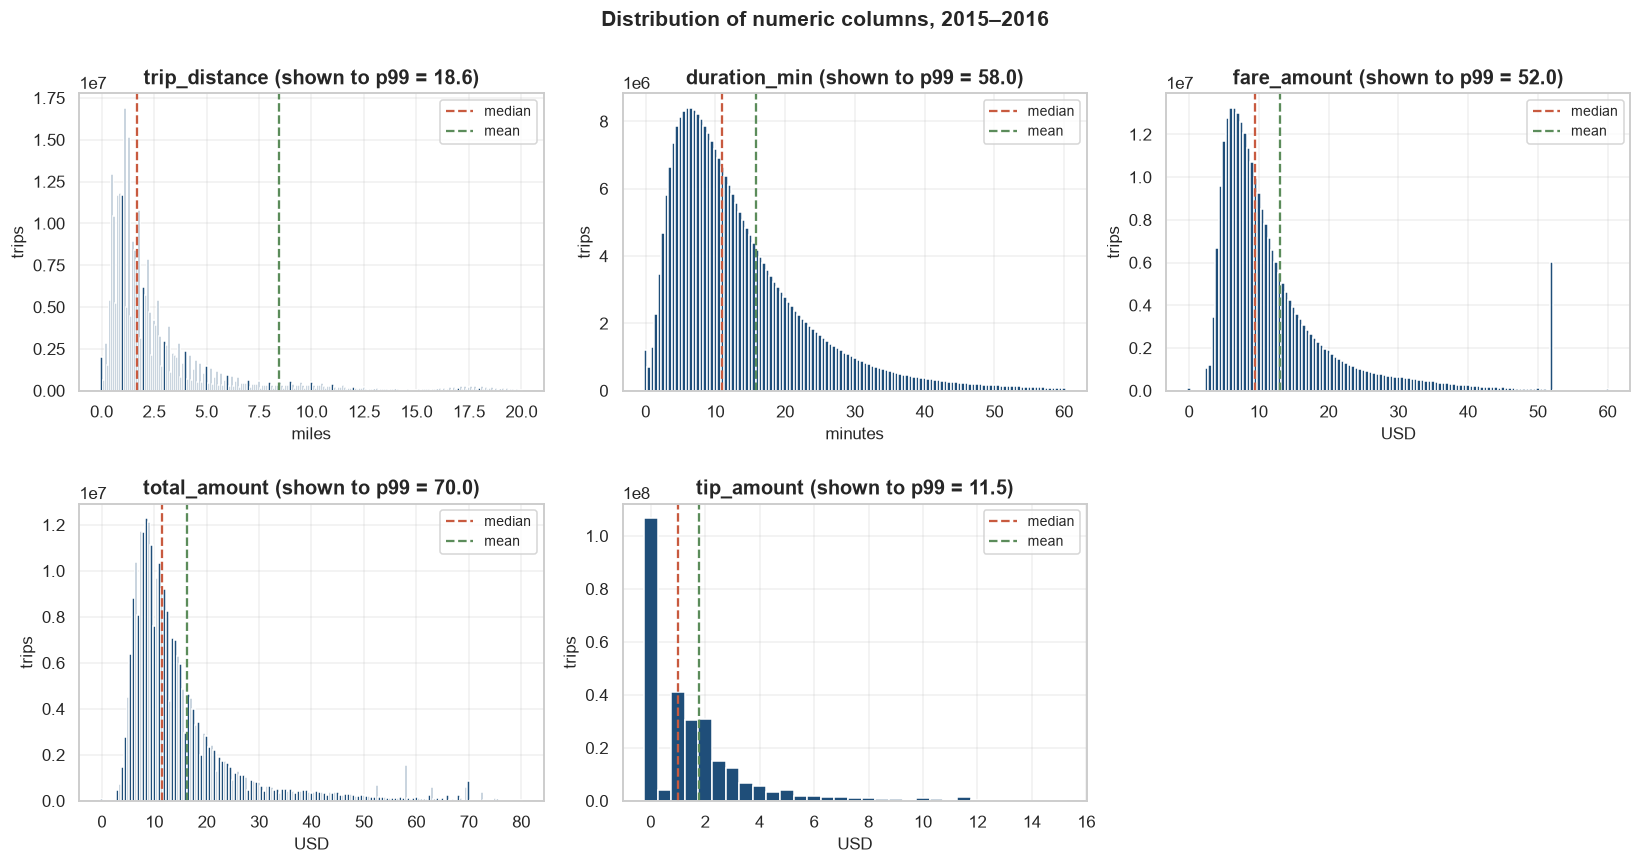

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

PLOT_LIMITS = {
    "trip_distance": (0, 20, "miles"),
    "duration_min": (0, 60, "minutes"),
    "fare_amount": (0, 60, "USD"),
    "total_amount": (0, 80, "USD"),
    "tip_amount": (0, 15, "USD"),
}

for axis, (name, (lower, upper, unit)) in zip(axes, PLOT_LIMITS.items()):
    histogram = histograms[name]
    window = histogram[(histogram["bin_start"] >= lower) & (histogram["bin_start"] <= upper)]

    axis.bar(window["bin_start"], window["rows"],
             width=window["bin_start"].diff().median(), color="#1f4e79")
    axis.axvline(numeric_profile.loc[name, "median"], color="#c85a3f",
                 linestyle="--", linewidth=1.5, label="median")
    axis.axvline(numeric_profile.loc[name, "mean"], color="#5b8c5a",
                 linestyle="--", linewidth=1.5, label="mean")
    axis.set_title(f"{name} (shown to p99 = {numeric_profile.loc[name, 'p99']})")
    axis.set_xlabel(unit)
    axis.set_ylabel("trips")
    axis.legend(fontsize=9)

axes[-1].axis("off")
fig.suptitle("Distribution of numeric columns, 2015–2016", fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_numeric_distributions.png", dpi=110, bbox_inches="tight")
plt.show()

The plots are cut at each column's p99; beyond that the corrupted maxima flatten everything into a single bar. Within that window all five distributions share the same shape: a sharp peak near the low end and a long right tail, with the mean line (green) sitting well to the right of the median (red). That gap is the visual definition of right skew, and it widens with the length of the tail — largest for `trip_distance`, where the mean of 8.44 falls outside the bulk of the data entirely.

Three features are visible here that the quantile table couldn't show.

`fare_amount` has an isolated spike at 52 dollars, standing alone with nothing around it. A fare that repeats exactly while its neighbours don't looks like a fixed price rather than a metered one; the first query below checks that against the rate code.

`tip_amount` has one bar at the bottom of the range that is larger than every other bar combined. With 50-cent bins, that bar covers everything from zero up to 49 cents, so the second query separates exact zeros from small tips and looks at how the non-zero tips are set.

`trip_distance` shows regular vertical striping across the whole range: some 0.1-mile bins are consistently fuller than their neighbours, so recorded distances favour certain values. The cause isn't visible in the data, but it means distance is less continuous than a summary table suggests.

In [14]:
fixed_fare_check = con.execute(f"""
    SELECT RatecodeID, COUNT(*) AS trips
    FROM read_parquet('{TRIP_FILES}')
    WHERE fare_amount = 52
    GROUP BY 1 ORDER BY 2 DESC
""").df()

display(fixed_fare_check.set_index("RatecodeID"))

,trips
RatecodeID,
2,5956361
1,50862
5,9656
3,924
4,702
99,215
6,8


Of the 6.02M trips with a fare of exactly 52 dollars, 5.96M — 99.0% — carry `RatecodeID = 2`, the JFK flat rate. The spike is a fixed price, not a metered fare.

In [15]:
zero_tips = con.execute(f"""
    SELECT
        COUNT(*) FILTER (WHERE tip_amount = 0)                      AS exactly_zero,
        COUNT(*) FILTER (WHERE tip_amount > 0 AND tip_amount < 0.5) AS between_0_and_050
    FROM read_parquet('{TRIP_FILES}')
""").df()

display(zero_tips)

,exactly_zero,between_0_and_050
0,106204348,623716


106.2M trips record a tip of exactly zero — 38% of all rows — and only 623,716 fall between zero and 50 cents, so the tall bar in the histogram is almost entirely exact zeros.

In [16]:
CARD_TIPS = f"""
    SELECT ROUND(tip_amount / fare_amount, 2) AS tip_to_fare
    FROM read_parquet('{TRIP_FILES}')
    WHERE payment_type = 1 AND tip_amount > 0 AND fare_amount BETWEEN 2.5 AND 500
"""

tip_to_fare = con.execute(f"""
    SELECT tip_to_fare, COUNT(*) AS trips
    FROM ({CARD_TIPS})
    GROUP BY 1 ORDER BY 2 DESC
    LIMIT 10
""").df()

tip_to_fare.set_index("tip_to_fare")

,trips
tip_to_fare,
0.22,29240789
0.21,22428213
0.23,17533501
0.24,10488712
0.25,6983796
0.27,6786582
0.26,5758525
0.20,4989027
0.28,4966732


In [17]:
tip_band = con.execute(f"""
    SELECT
        COUNT(*)                                                               AS card_trips_with_tip,
        ROUND(100.0 * COUNT(*) FILTER (WHERE tip_to_fare BETWEEN 0.20 AND 0.28)
              / COUNT(*), 1)                                                   AS pct_between_020_and_028
    FROM ({CARD_TIPS})
""").df()

tip_band

,card_trips_with_tip,pct_between_020_and_028
0,170952539,63.9


Among card payments with a tip, nine of the ten most common tip-to-fare ratios lie between 0.20 and 0.28, and 0.22 alone covers 29.2M trips. Across all 171.0M card trips with a tip, 63.9% fall inside that band. Why tips land in that range can't be seen in these records; preset options on the payment screen would be one possible explanation.

### What the distributions showed

All five numeric columns are right-skewed with long tails, so the median is the honest summary and the mean is not. Half of all trips are under 1.7 miles and 11 minutes — this is a short-hop service, and any model trained on it will spend most of its capacity on short rides.

The tails are contaminated rather than merely long. Distances of 59 million miles and fares approaching a million dollars aren't rare events, they're broken records, and they push the standard deviation for `trip_distance` to 8,327 against a p99 of 18.6. Rank-based statistics ignore them; moment-based statistics can't be used until the tail is cut. The outlier section takes that decision up directly.

Two structural findings carry into feature work. Tips are not spread evenly — 38% of all rows record exactly zero, and among card trips with a tip, 63.9% have a tip-to-fare ratio between 0.20 and 0.28. And the fare spike at 52 dollars, 99% of it JFK flat-rate trips, shows that fixed-price trips are mixed into the same columns as metered ones, so any distance-to-fare relationship holds for part of the data only.

Next comes the categorical side: how many classes each code column has, how unevenly they're distributed, and what that forces at encoding time.

## 5. Categorical variables

Five columns hold codes rather than measurements: `VendorID`, `RatecodeID`, `payment_type`, `store_and_fwd_flag`, and `passenger_count`. The last one is numeric in type but categorical in behaviour — a passenger count is a small integer chosen from a fixed set, not a continuous quantity.

Two things matter for each. How many distinct values does it actually take, and how evenly are trips spread across them? A column where one class holds 97% of the rows behaves almost like a constant, and rare classes create their own problem: a category with a few hundred rows out of 277M can't support a reliable estimate, and needs either merging or explicit handling before encoding.

The other question is whether the values match the published dictionary. Codes that appear in the data but not in the documentation are worth finding early.

In [18]:
CATEGORICAL_COLUMNS = ["VendorID", "RatecodeID", "payment_type",
                       "store_and_fwd_flag", "passenger_count"]

category_counts = {}
for column in CATEGORICAL_COLUMNS:
    category_counts[column] = con.execute(f"""
        SELECT
            {column}                                            AS value,
            COUNT(*)                                            AS trips,
            ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 3)  AS pct
        FROM read_parquet('{TRIP_FILES}')
        GROUP BY 1 ORDER BY trips DESC
    """).df()

summary = pd.DataFrame({
    "distinct_values": {c: len(t) for c, t in category_counts.items()},
    "top_class_pct": {c: t["pct"].iloc[0] for c, t in category_counts.items()},
    "classes_under_0.1pct": {c: int((t["pct"] < 0.1).sum()) for c, t in category_counts.items()},
})

summary

,distinct_values,top_class_pct,classes_under_0.1pct
VendorID,3,52.920,1
RatecodeID,7,97.296,3
payment_type,5,64.124,1
store_and_fwd_flag,2,99.292,0
passenger_count,10,70.675,4


In [19]:
pd.concat({column: table.set_index("value") for column, table in category_counts.items()}, names=["column"])

trips     pct
column             value                   
VendorID           2      146678478  52.920
                   1      130482261  47.076
                   3          10297   0.004
RatecodeID         1      269677476  97.296
                   2        5969550   2.154
                   5         874603   0.316
                   3         513835   0.185
                   4         116673   0.042
                   99         16022   0.006
                   6           2877   0.001
payment_type       1      177734229  64.124
                   2       98030307  35.368
                   3        1054205   0.380
                   4         352261   0.127
                   5             34   0.000
store_and_fwd_flag N      275208788  99.292
                   Y        1962248   0.708
passenger_count    1      195890304  70.675
                   2       39927011  14.405
                   5       14709793   5.307
                   3       11590053   4.182
                   6        9357403   3.376
                   4        5640850   2.035
                   0          54114   0.020
                   7            588   0.000
                   8            494   0.000
                   9            426   0.000

Every column here is imbalanced, and two of them contain codes the dictionary doesn't list.

`VendorID` has three values, not two. The documented providers 1 and 2 split the market almost evenly at 47% and 53%, but a third vendor appears in 10,297 trips. It isn't in the dictionary, and at 0.004% of the data it's small enough to have gone unnoticed in most analyses.

`RatecodeID` is the most skewed column in the dataset: 97.3% standard fares, and everything else fits in the remaining 2.7%. The value `RatecodeID = 99` appears 16,022 times with no documented meaning — the dictionary defines 1 through 6 only. Three classes sit below 0.1%, including code 6 with 2,877 trips out of 277M.

`payment_type` shows the same pattern at smaller scale. Card and cash account for 99.5%, while code 5 appears 34 times in two years. Codes 5 and 6 exist in the dictionary but are effectively absent from the data.

`passenger_count` runs from 0 to 9, with 70.7% of trips carrying a single passenger. Counts above six are vanishingly rare — 588 trips with seven, 494 with eight, 426 with nine — and exceed what a yellow cab is licensed to carry, so they're data entry errors rather than unusually full taxis. The 54,114 trips recording zero passengers are impossible for a completed, paid fare, and are another instance of missing information written as a number rather than a null.

`store_and_fwd_flag` has only two classes but 99.3% are N. As a feature it carries almost no variance; as a diagnostic it marks the 1.96M trips where the vehicle lost its connection and buffered the record, which the location section revisits.

In [20]:
passenger_profile = con.execute(f"""
    SELECT
        passenger_count,
        COUNT(*)                                                      AS trips,
        ROUND(100.0 * COUNT(*) FILTER (WHERE VendorID = 1) / COUNT(*), 1) AS vendor1_pct,
        ROUND(100.0 * COUNT(*) FILTER (
            WHERE EXTRACT(dow FROM tpep_pickup_datetime) BETWEEN 1 AND 5) / COUNT(*), 1) AS weekday_pct,
        ROUND(100.0 * COUNT(*) FILTER (
            WHERE EXTRACT(dow FROM tpep_pickup_datetime) BETWEEN 1 AND 5
              AND EXTRACT(hour FROM tpep_pickup_datetime) BETWEEN 7 AND 8) / COUNT(*), 1) AS school_morning_pct,
        ROUND(100.0 * COUNT(*) FILTER (
            WHERE EXTRACT(dow FROM tpep_pickup_datetime) BETWEEN 1 AND 5
              AND EXTRACT(hour FROM tpep_pickup_datetime) BETWEEN 15 AND 16) / COUNT(*), 1) AS school_afternoon_pct,
        ROUND(MEDIAN(trip_distance), 2)                               AS median_distance,
        ROUND(MEDIAN(total_amount), 2)                                AS median_total
    FROM read_parquet('{TRIP_FILES}')
    WHERE passenger_count BETWEEN 1 AND 6
      AND trip_distance BETWEEN 0.1 AND 100
      AND total_amount BETWEEN 2.5 AND 500
    GROUP BY 1 ORDER BY 1
""").df()

display(passenger_profile.set_index("passenger_count"))

,trips,vendor1_pct,weekday_pct,school_morning_pct,school_afternoon_pct,median_distance,median_total
passenger_count,,,,,,,
1,194257223,53.7,72.6,7.7,6.4,1.70,11.80
2,39668349,45.1,67.3,5.2,6.5,1.80,12.30
3,11523760,39.6,65.9,5.1,6.6,1.80,12.30
4,5604934,44.2,64.3,4.7,6.2,1.80,12.30
5,14631383,0.5,70.7,7.0,6.2,1.77,12.25
6,9311857,0.3,71.0,7.7,6.5,1.74,11.80


The three hypotheses a passenger-count pattern usually suggests — school runs, shift transport, airport groups — all predict distinctive timing or distance. Neither appears. Trips with five or six passengers run on weekdays 71% of the time (single-passenger trips: 72.6%), peak at the same hours, and have a median distance of 1.74–1.77 miles against 1.70 for single passengers. By every behavioural measure they look like ordinary short city trips.

The difference is in who recorded them. Vendor 1 accounts for 53.7% of single-passenger trips but only 0.5% and 0.3% of five- and six-passenger ones — roughly 100,000 rows out of 24M (0.5% of 14.6M plus 0.3% of 9.3M). The vendor split also shifts across the middle of the range, dropping to 39.6% at three passengers.

So `passenger_count` is not an independent property of the trip; it partly encodes which provider wrote the record. Why the two systems differ can't be determined from this data. The consequence for modeling is a confound rather than a redundancy: a model learning something from `passenger_count = 5` may in fact be learning `VendorID = 2`.

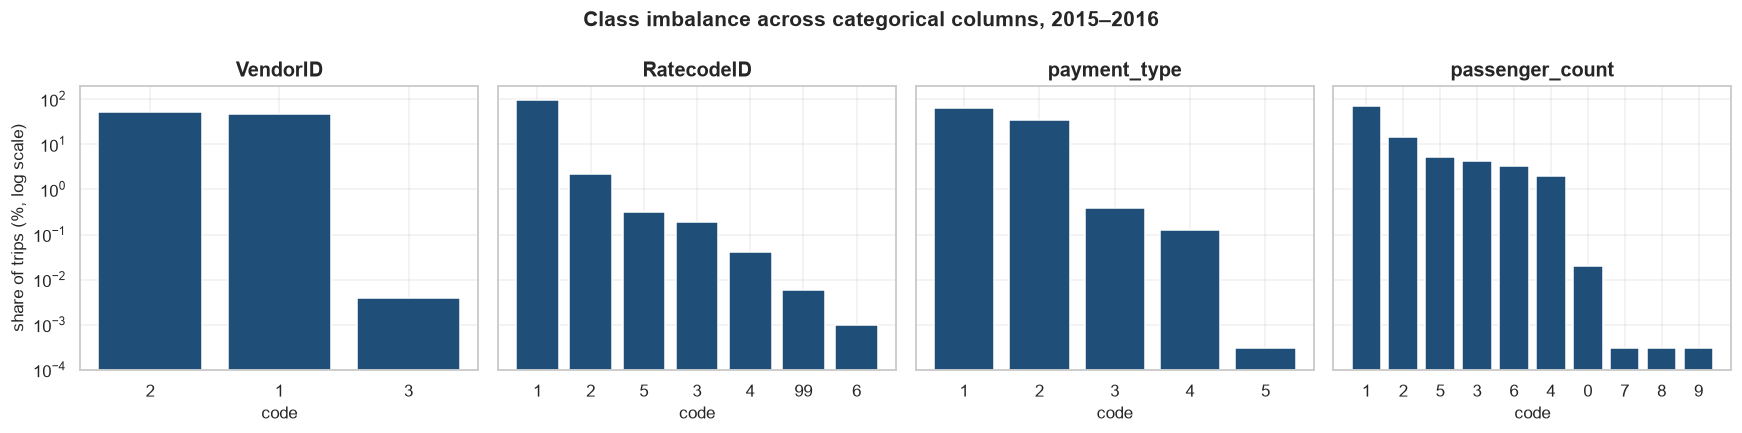

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)

PLOT_COLUMNS = ["VendorID", "RatecodeID", "payment_type", "passenger_count"]
AXIS_FLOOR = 1e-4
BAR_FLOOR = 3e-4

for axis, column in zip(axes, PLOT_COLUMNS):
    table = category_counts[column].sort_values("pct", ascending=False)

    axis.bar(table["value"].astype(str), table["pct"].clip(lower=BAR_FLOOR),
             color="#1f4e79")
    axis.set_yscale("log")
    axis.set_ylim(AXIS_FLOOR, 200)
    axis.set_title(column)
    axis.set_xlabel("code")

axes[0].set_ylabel("share of trips (%, log scale)")
fig.suptitle("Class imbalance across categorical columns, 2015–2016",
             fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_categorical_imbalance.png", dpi=110, bbox_inches="tight")
plt.show()

A log scale is the only way to put these columns on one axis: the largest class holds 97.3% and the smallest sits around one in a million. The shortest bars — `payment_type` 5 and `passenger_count` 7 to 9 — are pinned to a visible minimum rather than drawn to scale; their actual trip counts appear in each column's own table above.

`RatecodeID` declines steadily from 97.3% to 0.001% across all seven classes. In `payment_type` the two largest classes hold 64.1% and 35.4%, while the third holds 0.38%. `VendorID` follows the same pattern: 52.9% and 47.1% for the first two, 0.004% for the third. `passenger_count` declines more evenly, from 70.7% down to 2.0% across six classes, then falls to 0.02% and below for the last four.

For encoding this means the largest and smallest classes can't be handled the same way. A category with 2,877 rows out of 277M cannot support a stable estimate — one-hot encoding it produces a column that is zero for 99.999% of rows, and any model fitting it is fitting noise. The options are merging the rare classes into a single "other" level, or keeping only those that carry a distinct business meaning. `RatecodeID` 2 and 3 are worth keeping separate despite their size because they mark airport trips with fixed fares; codes 4, 6, and 99 are candidates for merging.

### What the categorical columns showed

Every code column is dominated by one class, and the smallest classes are too thin to model directly. `RatecodeID` is the extreme case at 97.3% standard fares, but the pattern holds across all five columns.

Two codes appear in the data without appearing in the dictionary: `VendorID = 3` with 10,297 trips and `RatecodeID = 99` with 16,022. Neither is large, but both would reach a model as legitimate categories unless caught here.

The most consequential finding isn't about any single column. `passenger_count` turned out to depend on which vendor recorded the trip rather than on the trip itself — five- and six-passenger rides come almost entirely from one provider while matching single-passenger rides on timing, distance, and fare. That makes `VendorID` a variable to check against, not just a feature to include. The same check is worth repeating whenever a group difference appears later in this notebook.

Encoding decisions follow from the imbalance: merge `RatecodeID` 4, 6 and 99, keep 2 and 3 separate for the airport signal, and treat `passenger_count` zeros as missing rather than as a count.

Outliers come next. The numeric section showed the tails are contaminated; the question now is which detection method fits a right-skewed distribution, and what to do with what it flags.

## 6. Outliers

The numeric section established that the tails contain broken records — distances in the millions of miles, fares approaching a million dollars. The question here is how to find them systematically, and what to do once found.

Three detection methods get compared. The interquartile range rule flags anything beyond 1.5 times the IQR above the third quartile. The three-sigma rule flags anything more than three standard deviations from the mean. The percentile cut simply takes everything above p99. A table shows how many rows each method flags, then the thresholds are drawn on the distributions to see where each one falls. After that I repeated the same methods with different coefficients and scales, and compared where the bounds fall with the airport trips.

The second question matters more than the first. An extreme value can mean three different things: a recording failure, a genuine but unusual trip, or a category the dataset mixes in without labelling. Each calls for different handling, and a single threshold can't tell them apart.

In [22]:
OUTLIER_TARGETS = ["trip_distance", "duration_min", "fare_amount", "total_amount"]

thresholds = {}
for column in OUTLIER_TARGETS:
    histogram = histograms[column]
    stats = numeric_profile.loc[column]

    total_rows = histogram["rows"].sum()
    cumulative = histogram["rows"].cumsum()
    q1 = histogram["bin_start"].iloc[cumulative.searchsorted(0.25 * total_rows)]
    q3 = histogram["bin_start"].iloc[cumulative.searchsorted(0.75 * total_rows)]

    bounds = {
        "IQR (Q3 + 1.5 IQR)": q3 + 1.5 * (q3 - q1),
        "3 sigma (mean + 3 std)": stats["mean"] + 3 * stats["std"],
        "percentile (p99)": stats["p99"],
    }

    thresholds[column] = {
        f"{name} | bound": round(bound, 2) for name, bound in bounds.items()
    } | {
        f"{name} | flagged %": round(
            100 * histogram.loc[histogram["bin_start"] > bound, "rows"].sum() / total_rows, 2
        )
        for name, bound in bounds.items()
    }

outlier_comparison = pd.DataFrame(thresholds).T
display(outlier_comparison)

,IQR (Q3 + 1.5 IQR) | bound,3 sigma (mean + 3 std) | bound,percentile (p99) | bound,IQR (Q3 + 1.5 IQR) | flagged %,3 sigma (mean + 3 std) | flagged %,percentile (p99) | flagged %
trip_distance,6.50,24989.53,18.6,10.21,0.00,0.97
duration_min,35.25,164.76,58.0,5.07,0.13,0.99
fare_amount,27.75,452.53,52.0,8.13,0.00,0.62
total_amount,31.00,867.42,70.0,9.21,0.00,0.69


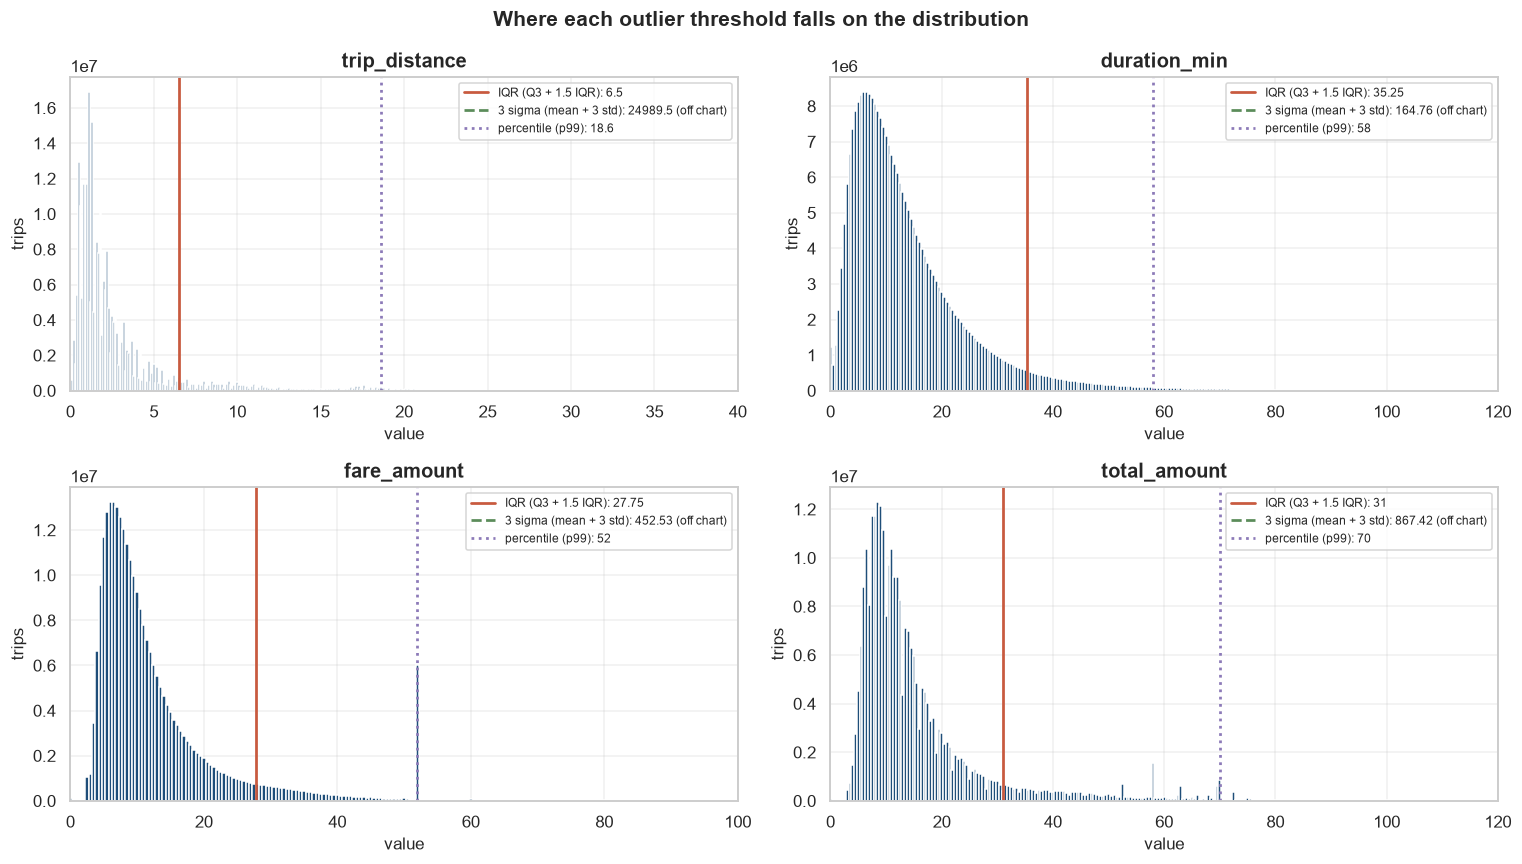

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
LINE_STYLES = {
    "IQR (Q3 + 1.5 IQR)": ("#c85a3f", "-"),
    "3 sigma (mean + 3 std)": ("#5b8c5a", "--"),
    "percentile (p99)": ("#8c7ab8", ":"),
}
VIEW_LIMITS = {"trip_distance": 40, "duration_min": 120,
               "fare_amount": 100, "total_amount": 120}

for axis, column in zip(axes.flatten(), OUTLIER_TARGETS):
    histogram = histograms[column]
    upper = VIEW_LIMITS[column]
    window = histogram[(histogram["bin_start"] >= 0) & (histogram["bin_start"] <= upper)]

    axis.bar(window["bin_start"], window["rows"],
             width=window["bin_start"].diff().median(), color="#1f4e79")
    axis.set_xlim(0, upper)

    for method, (colour, style) in LINE_STYLES.items():
        bound = outlier_comparison.loc[column, f"{method} | bound"]
        if bound <= upper:
            axis.axvline(bound, color=colour, linestyle=style, linewidth=1.8,
                         label=f"{method}: {bound:g}")
        else:
            axis.plot([], [], color=colour, linestyle=style, linewidth=1.8,
                      label=f"{method}: {bound:g} (off chart)")

    axis.set_title(column)
    axis.set_xlabel("value")
    axis.set_ylabel("trips")
    axis.legend(fontsize=8)

fig.suptitle("Where each outlier threshold falls on the distribution",
             fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_outlier_thresholds.png", dpi=110, bbox_inches="tight")
plt.show()

The three methods land in completely different places, and only one of them lands anywhere sensible.

The IQR rule cuts at 6.5 miles and flags 10.2% of all trips — 28 million rows. The line sits inside the visible body of the distribution, not past it. Every airport transfer, every trip to an outer borough is marked as anomalous. The three-sigma rule fails in the opposite direction: its threshold for `trip_distance` is 24,989 miles, so far beyond the data that it flags 0.00% of rows.

Both failures have the same cause. IQR and three-sigma are built for symmetric distributions, where roughly equal mass sits either side of the centre. Section 4 established that none of these columns is symmetric. On a right-skewed distribution the IQR rule treats the entire legitimate tail as anomalous, while three-sigma inherits a standard deviation that the corrupted records themselves inflated — the 8,327 figure for `trip_distance` comes from the very rows the method is supposed to catch.

With default parameters, the percentile cut is the only one that behaves. It flags around 1% by construction and its threshold sits where the distribution has genuinely thinned out.

The `fare_amount` panel shows something the thresholds can't handle. A single isolated bar stands at 52 dollars, right at the p99 line, with almost nothing on either side of it. That is the JFK flat fare identified in Section 4 — around six million trips priced identically. No statistical threshold can classify that correctly: it's neither an error nor a rare event, it's a separate pricing category mixed into the same column.

### Sensitivity to parameter and scale

The comparison above tested the methods with their default parameters. That is not enough to discard a method, because a method's logic and its parameter are two different things. The logic of the IQR rule is to flag values far from the body of the distribution. The 1.5 coefficient, however, was chosen for the normal distribution: there, Q3 + 1.5 IQR sits about 2.7 standard deviations above the mean. The problem with the three-sigma rule is likewise not the rule but the spread measure it uses. The standard deviation is inflated by the very corrupted records it should catch.

So I tested both methods again with different parameters. For IQR I tried three coefficients (1.5, 3 and 5) on two scales (raw and log). Because log is a monotonic transformation, the quartiles on the log scale equal the logarithms of the quartiles, so I computed the bound directly as Q3 × (Q3 / Q1)^k. In the sigma rule I replaced the standard deviation with the MAD (median absolute deviation), which corrupted records do not inflate, and set the bound at median + k × 1.4826 × MAD. The 1.4826 factor puts the MAD on the same scale as the standard deviation under a normal distribution. I tried the MAD on the raw and the log scale as well. On the log scale, zero and negative values do not enter the calculation. I computed every value from the Section 4 histograms, at the same bin precision.

Before looking at the table I set two conditions for saying that a bound works on this data. First, a legitimate structure must not end up above the bound. For this I used the 52-dollar JFK flat fare as the reference. Second, the flagged share must be of the same size as p99, around 1%.

In [24]:
import math


def binned_quantile(values, rows, q):
    """Quantile of a binned distribution, exact to the bin width."""
    return values.iloc[rows.cumsum().searchsorted(q * rows.sum())]


def binned_mad(values, rows, centre):
    """Median absolute deviation of a binned distribution."""
    deviation = pd.DataFrame({"dev": (values - centre).abs(), "rows": rows}).groupby("dev")["rows"].sum()
    return deviation.index[deviation.cumsum().searchsorted(0.5 * rows.sum())]


sensitivity_rows = []
for column in OUTLIER_TARGETS:
    values, rows = histograms[column]["bin_start"], histograms[column]["rows"]
    q1, median, q3, p99 = (binned_quantile(values, rows, q) for q in (0.25, 0.50, 0.75, 0.99))
    mad = binned_mad(values, rows, median)

    positive = values > 0
    log_values = values[positive].map(math.log)
    log_median = binned_quantile(log_values, rows[positive], 0.50)
    log_mad = binned_mad(log_values, rows[positive], log_median)

    candidates = (
        [("IQR, raw", k, q3 + k * (q3 - q1)) for k in (1.5, 3, 5)]
        + [("IQR, log", k, q3 * (q3 / q1) ** k) for k in (1.5, 3, 5)]
        + [("MAD, raw", k, median + k * 1.4826 * mad) for k in (3, 5, 7)]
        + [("MAD, log", k, math.exp(log_median + k * 1.4826 * log_mad)) for k in (3, 5, 7)]
        + [("percentile (p99)", None, p99)]
    )
    for method, k, bound in candidates:
        sensitivity_rows.append({
            "column": column, "method": method, "k": k, "bound": round(bound, 2),
            "flagged %": round(100 * rows[values > bound].sum() / rows.sum(), 2),
        })

sensitivity = (pd.DataFrame(sensitivity_rows)
               .pivot(index=["method", "k"], columns="column", values=["bound", "flagged %"]))
display(sensitivity)

bound                                         \
column               duration_min fare_amount total_amount trip_distance   
method           k                                                         
IQR, log         1.5        82.95       52.58        51.70         18.32   
                 3.0       382.25      184.34       152.72        104.86   
                 5.0      2931.35      981.70       647.34       1073.74   
IQR, raw         1.5        35.25       27.75        31.00          6.50   
                 3.0        52.50       40.50        44.50          9.80   
                 5.0        75.50       57.50        62.50         14.20   
MAD, log         3.0       111.07       51.38        57.77         21.26   
                 5.0       518.91      158.29       169.45        114.56   
                 7.0      2424.22      487.71       497.03        617.25   
MAD, raw         3.0        35.46       25.07        29.29          5.70   
                 5.0        51.77       35.45        41.15          8.37   
                 7.0        68.08       45.82        53.01         11.04   
percentile (p99) NaN        58.00       52.00        70.00         18.60   

                        flagged %                                         
column               duration_min fare_amount total_amount trip_distance  
method           k                                                        
IQR, log         1.5         0.26        0.60         3.69          1.12  
                 3.0         0.13        0.01         0.03          0.00  
                 5.0         0.00        0.00         0.00          0.00  
IQR, raw         1.5         5.07        8.13         9.21         10.21  
                 3.0         1.42        3.77         4.96          5.82  
                 5.0         0.36        0.46         1.91          2.97  
MAD, log         3.0         0.15        2.81         2.87          0.30  
                 5.0         0.12        0.02         0.02          0.00  
                 7.0         0.00        0.00         0.00          0.00  
MAD, raw         3.0         5.07        9.64        10.17         11.92  
                 5.0         1.52        4.98         5.86          7.75  
                 7.0         0.54        3.15         3.33          4.47  
percentile (p99) NaN         0.99        0.62         0.69          0.97

The table shows that what broke the default results was not the logic of the methods. On the raw scale, raising the coefficient alone is not enough: even at k = 5 the distance bound is 14.2 miles and 2.97% of rows are flagged. On the log scale, the default 1.5 coefficient gives bounds very close to p99: 18.32 miles for distance (1.12%), 52.58 dollars for fare (0.6%) and 82.95 minutes for duration (0.26%). The MAD tells the same story. On the raw scale the MAD is not inflated by corrupted records the way the standard deviation is. But as a symmetric measure, even at k = 7 it keeps the fare bound at 45.82 dollars and flags 3.15% of rows. On the log scale at k = 3, the distance bound is 21.26 miles (0.3%) and the duration bound 111.07 minutes (0.15%). On this skewed data, IQR needed the log scale and the sigma rule needed the MAD.

The first condition of the decision rule turned out more fragile than I expected. The JFK flat fare falls right between the 1% bounds of the two log methods. Log-scale IQR leaves the 52-dollar fare outside by 58 cents, while log-scale MAD takes it inside by 62 cents (51.38 dollars, 2.81%). For the total amount, both log methods flag far more than 1% (3.69% and 2.87%). That a difference of less than a dollar decides the outcome raised the question of what a bound at this level actually separates.

Wider coefficients form a second tier. On the log scale, IQR with k = 3 and MAD with k = 5 give bounds of 104.86 and 114.56 miles for distance and 184.34 and 158.29 dollars for fare, and flag at most 0.13% of rows. To see what the trips above the two tiers are, I computed the share of airport trips in each band. I counted a trip as an airport trip when its pickup or dropoff zone is JFK, LaGuardia or Newark. I took the band limits from the log-scale IQR bounds in the table.

In [25]:
AIRPORTS = "('JFK Airport', 'LaGuardia Airport', 'Newark Airport')"

con.execute(f"""
    CREATE OR REPLACE VIEW airport_trips AS
    SELECT
        t.trip_distance,
        t.fare_amount,
        COALESCE(pu.Zone IN {AIRPORTS} OR do_zone.Zone IN {AIRPORTS}, false) AS is_airport
    FROM read_parquet('{TRIP_FILES}') AS t
    LEFT JOIN read_csv_auto('{ZONE_LOOKUP}') AS pu      ON t.PULocationID = pu.LocationID
    LEFT JOIN read_csv_auto('{ZONE_LOOKUP}') AS do_zone ON t.DOLocationID = do_zone.LocationID
""");

In [26]:
def airport_share_by_band(column, lower, upper):
    """Trips and airport share below, between and above two bounds."""
    return con.execute(f"""
        SELECT
            CASE WHEN {column} <= {lower} THEN '1: below the k=1.5 bound'
                 WHEN {column} <= {upper} THEN '2: between the two bounds'
                 ELSE '3: above the k=3 bound' END                          AS band,
            COUNT(*)                                                        AS trips,
            ROUND(100.0 * AVG(CAST(is_airport AS INTEGER)), 1)              AS airport_pct
        FROM airport_trips
        WHERE {column} > 0
        GROUP BY 1 ORDER BY 1
    """).df().set_index("band")


log_iqr = sensitivity["bound"].loc["IQR, log"]
airport_bands = pd.concat({
    column: airport_share_by_band(column, log_iqr.loc[1.5, column], log_iqr.loc[3.0, column])
    for column in ["trip_distance", "fare_amount"]
}, axis=1)
display(airport_bands)

trip_distance             fare_amount            
                                  trips airport_pct       trips airport_pct
band                                                                       
1: below the k=1.5 bound      272273201         5.7   275331823         6.4
2: between the two bounds       3244383        90.9     1633188        66.0
3: above the k=3 bound             3030        49.9       28842        28.3

The two tiers separate different things. For distance, 90.9% of the 3,244,383 trips between the two bounds start or end at an airport. Below the lower bound the share is only 5.7%. Fare shows the same picture: 66.0% of the 1,633,188 trips between the two bounds are airport trips. The top 1% of this data consists largely of airport trips. A statistical bound set at the 1% level, whatever the method, separates long and expensive trips rather than anomalous ones.

Above the second tier the group is smaller but mixed. There are 3,030 trips above the distance bound and 28,842 above the fare bound, and 49.9% and 28.3% of them, respectively, are airport trips. In this band, plainly corrupted records of millions of miles sit next to airport trips. An airport share far above the 5.7% of the lower band suggests that part of these records may be genuine long trips. A bound that looks at a single column cannot separate the two. Doing so requires evaluating distance together with duration and fare.

### What to do with them

No single threshold works here, because "outlier" covers three different situations in this data. Each needs separate handling.

**Physically impossible values get removed.** A trip of 59 million miles, a fare of 825,998 dollars, a dropoff before its pickup — these cannot describe a real journey. They are recording failures, and keeping them contaminates every mean and standard deviation downstream. The filter is domain-based rather than statistical: distance between 0 and roughly 100 miles, duration between one minute and 24 hours, amounts within plausible fare limits. The k = 3 bound of log-scale IQR falls very close to this domain limit, at 104.86 miles for distance. Still, about half of the records above that bound are airport trips, so whether a record is impossible should be decided from its consistency with duration and fare, not from the distance alone.

**Rare but legitimate trips stay.** The tail between p99 and the physical limits is real business. Airport trips (90.9% of the distance band between the two log IQR bounds), long outer-borough rides, trips during unusual traffic — all genuine, all worth modelling. Removing them would train a model that only understands the median trip and fails on exactly the journeys that generate the most revenue.

**Mixed categories get labelled, not cut.** The 52-dollar spike isn't an outlier at all; it's a different pricing regime sitting in the same column. The right treatment is a flag — `RatecodeID` already provides one — so that fixed-fare trips can be separated from metered ones rather than silently averaged together.

For modelling this means two derived columns rather than a filter: one marking records that failed the physical checks, and one marking fixed-fare trips. Both preserve the row count while letting any downstream step decide what to include. The decision of where exactly to cut belongs to the modelling stage, which knows what the target variable is; this section's job is to establish that a statistical bound is meaningful only when it is set on the right scale and calibrated against a legitimate structure in the data, and that even the best-calibrated bound needs domain limits and category flags alongside.

### What the outlier analysis showed

With default parameters the three methods gave three answers to the same question: IQR flagged 28M rows, three-sigma flagged none, and the percentile cut flagged 2.7M. The cause of that spread was not the logic of the methods but the choice of scale and parameter. IQR on the log scale with the default coefficient, and a sigma rule that uses the MAD instead of the standard deviation, gave bounds very close to p99.

The real lesson is where the bound falls. Every bound at the 1% level, whatever the method, separates airport trips: 90.9% of that distance band are airport trips. The 52-dollar JFK fare sits inside one method's bound and outside the other's, by less than a dollar. A detection method produces a trustworthy number only when it is set on a scale that suits the shape of the distribution and calibrated against a legitimate structure in the data. When the default parameter fails, the parameter should be tested before the method is discarded.

The handling decision splits three ways rather than one. Impossible values get removed, rare but real trips stay, and mixed pricing categories get flagged instead of cut. None of this requires deleting rows now — two derived columns carry the information forward and leave the cut point to the modelling stage, which will know what the target variable is.

Correlation comes next: which numeric columns duplicate each other, and which relationships would leak information into a model that used them.

## 7. Correlation

Two questions here. Which numeric columns carry the same information, and which relationships would cause a model to fail in production despite scoring well in testing.

Pearson and Spearman get computed side by side. Pearson measures linear association and is sensitive to extreme values; Spearman works on ranks, so it captures any monotonic relationship and ignores how far out the outliers sit. Where the two agree, the relationship is linear. Where they diverge, the gap says which of the two assumptions failed — and that gap is more informative than either coefficient alone.

Pearson runs across all 277M rows. Spearman requires ranking every value, which has the same memory cost as the exact quantiles in Section 4, so it runs on a 3M-row sample drawn with a fixed seed.

In [27]:
CLEAN_TRIPS = f"""
    SELECT
        trip_distance,
        fare_amount,
        tip_amount,
        total_amount,
        passenger_count,
        date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime) / 60.0 AS duration_min
    FROM read_parquet('{TRIP_FILES}')
    WHERE trip_distance BETWEEN 0.1 AND 100
      AND fare_amount BETWEEN 2.5 AND 500
      AND total_amount BETWEEN 2.5 AND 500
      AND date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime) BETWEEN 60 AND 10800
"""

pearson = con.execute(f"""
    SELECT
        ROUND(CORR(trip_distance, fare_amount), 3)   AS distance_fare,
        ROUND(CORR(trip_distance, total_amount), 3)  AS distance_total,
        ROUND(CORR(fare_amount, total_amount), 3)    AS fare_total,
        ROUND(CORR(fare_amount, tip_amount), 3)      AS fare_tip,
        ROUND(CORR(duration_min, fare_amount), 3)    AS duration_fare,
        ROUND(CORR(duration_min, trip_distance), 3)  AS duration_distance,
        ROUND(CORR(passenger_count, total_amount), 3) AS passengers_total
    FROM ({CLEAN_TRIPS})
""").df().T

pearson.columns = ["pearson"]
display(pearson)

,pearson
distance_fare,0.949
distance_total,0.939
fare_total,0.982
fare_tip,0.571
duration_fare,0.864
duration_distance,0.781
passengers_total,0.011


Pearson correlation across all 277M rows, after filtering out the physically impossible values identified earlier. Three pairs sit above 0.93; `passenger_count` shows almost no linear relationship with the total amount. Interpretation waits for Spearman, since Pearson alone can't separate a genuine linear relationship from one inflated by extreme values.

In [28]:
spearman = con.execute(f"""
    WITH sample AS (
        {CLEAN_TRIPS}
        USING SAMPLE 3000000 ROWS (reservoir, 42)
    ),
    ranked AS (
        SELECT
            RANK() OVER (ORDER BY trip_distance)   AS r_distance,
            RANK() OVER (ORDER BY fare_amount)     AS r_fare,
            RANK() OVER (ORDER BY tip_amount)      AS r_tip,
            RANK() OVER (ORDER BY total_amount)    AS r_total,
            RANK() OVER (ORDER BY passenger_count) AS r_passengers,
            RANK() OVER (ORDER BY duration_min)    AS r_duration
        FROM sample
    )
    SELECT
        ROUND(CORR(r_distance, r_fare), 3)     AS distance_fare,
        ROUND(CORR(r_distance, r_total), 3)    AS distance_total,
        ROUND(CORR(r_fare, r_total), 3)        AS fare_total,
        ROUND(CORR(r_fare, r_tip), 3)          AS fare_tip,
        ROUND(CORR(r_duration, r_fare), 3)     AS duration_fare,
        ROUND(CORR(r_duration, r_distance), 3) AS duration_distance,
        ROUND(CORR(r_passengers, r_total), 3)  AS passengers_total
    FROM ranked
""").df().T

spearman.columns = ["spearman"]
display(spearman)

,spearman
distance_fare,0.930
distance_total,0.914
fare_total,0.977
fare_tip,0.314
duration_fare,0.962
duration_distance,0.831
passengers_total,0.021


Spearman correlation on a 3M-row sample, computed on ranks rather than raw values. Two pairs move noticeably against their Pearson counterparts: `fare_tip` drops and `duration_fare` rises. The comparison below puts both methods side by side.

In [29]:
correlations = pd.concat([pearson, spearman], axis=1)
correlations["difference"] = (correlations["spearman"] - correlations["pearson"]).round(3)

display(correlations.sort_values("difference"))

,pearson,spearman,difference
fare_tip,0.571,0.314,-0.257
distance_total,0.939,0.914,-0.025
distance_fare,0.949,0.930,-0.019
fare_total,0.982,0.977,-0.005
passengers_total,0.011,0.021,0.010
duration_distance,0.781,0.831,0.050
duration_fare,0.864,0.962,0.098


Sorted by the gap between the two methods. The chart below shows the same comparison visually.

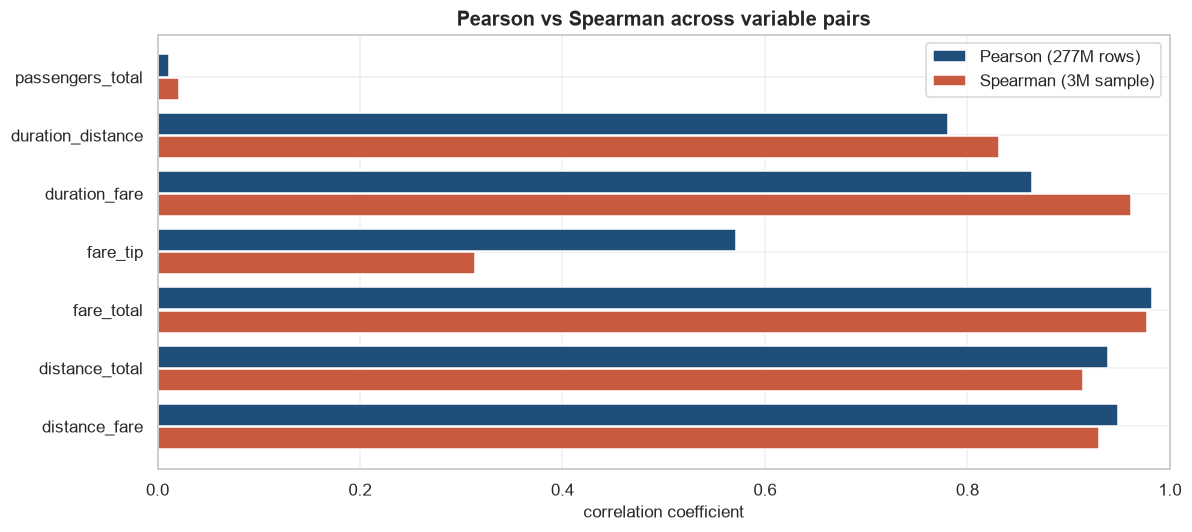

In [30]:
fig, axis = plt.subplots(figsize=(11, 5))

positions = range(len(correlations))
offset = 0.2

axis.barh([p + offset for p in positions], correlations["pearson"],
          height=0.38, color="#1f4e79", label="Pearson (277M rows)")
axis.barh([p - offset for p in positions], correlations["spearman"],
          height=0.38, color="#c85a3f", label="Spearman (3M sample)")

axis.set_yticks(list(positions))
axis.set_yticklabels(correlations.index)
axis.set_xlabel("correlation coefficient")
axis.set_xlim(0, 1)
axis.set_title("Pearson vs Spearman across variable pairs")
axis.legend()

fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_correlation_comparison.png", dpi=110, bbox_inches="tight")
plt.show()

In five of the seven pairs the two methods differ by less than 0.05, which means those relationships are linear and the coefficients can be read at face value. Two pairs differ by more, and the difference changes what they mean.

`fare_tip` is 0.571 under Pearson and 0.314 under Spearman — the largest gap in the table, and moderate at best under either method. The two queries below look at what weakens it: how tips are recorded under each payment type, and how the correlation changes when special-rate trips (airports among them) or cash trips are left out.

`duration_fare` moves the other way: 0.864 under Pearson, 0.962 under Spearman. A Spearman value that much higher means the relationship is monotonic but not linear — longer trips always cost more, but not at a constant rate per minute. Fixed-fare airport trips are one visible source: 5.96M of the 5.97M JFK flat-rate trips are billed at exactly 52 dollars, whatever their duration.

The three pairs above 0.9 in both methods are columns that substitute for each other — multicollinearity. `fare_total` at 0.977 is the clearest: `total_amount` is `fare_amount` plus fixed components, so the two columns are largely the same variable. Only one belongs in a model.

`distance_fare` at 0.930 is a different problem, and the more dangerous one. The relationship is real, but `trip_distance` is only known once the trip ends. Using it to predict fare would produce a model that scores well in testing and cannot run in production, where the prediction is needed at pickup, before the distance exists. This is the leakage risk the section set out to find.

In [31]:
tip_by_payment = con.execute(f"""
    SELECT
        payment_type,
        COUNT(*)                                                            AS trips,
        ROUND(100.0 * COUNT(*) FILTER (WHERE tip_amount = 0) / COUNT(*), 1) AS zero_tip_pct,
        ROUND(AVG(tip_amount), 2)                                           AS mean_tip,
        ROUND(AVG(fare_amount), 2)                                          AS mean_fare
    FROM read_parquet('{TRIP_FILES}')
    WHERE trip_distance BETWEEN 0.1 AND 100
      AND fare_amount BETWEEN 2.5 AND 500
      AND total_amount BETWEEN 2.5 AND 500
      AND date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime) BETWEEN 60 AND 10800
    GROUP BY 1 ORDER BY trips DESC
""").df()

display(tip_by_payment.set_index("payment_type"))

,trips,zero_tip_pct,mean_tip,mean_fare
payment_type,,,,
1,176601337,3.7,2.71,13.40
2,96448973,100.0,0.00,12.06
3,702227,99.9,0.00,15.04
4,259429,99.9,0.00,15.11
5,21,81.0,1.85,23.84


The split is absolute. Card payments (`payment_type = 1`) leave the tip at zero in only 3.7% of trips, averaging 2.71 dollars. Cash payments (`payment_type = 2`) record zero in 100% of 96.4 million trips. The no-charge (3) and dispute (4) records behave the same way. `payment_type = 5` is defined as "unknown" in the dictionary and survives the filters in only 21 rows, too small to support any conclusion.

Mean fares are 13.40 for card and 12.06 for cash, close enough that the two groups are taking comparable trips. Nothing here says cash passengers tip less; whatever they tip is simply not recorded.

The consequence for modelling is that `tip_amount` only carries information on the card subset. Fitting it across all rows means fitting a variable that is structurally zero for a third of the data, and a model would learn to predict `payment_type` — a column already present — rather than tipping behaviour. Any tip analysis has to be scoped to card payments (`payment_type = 1`) and reported as such.

In [32]:
tip_correlation = con.execute(f"""
    SELECT
        ROUND(CORR(fare_amount, tip_amount), 3)                                      AS all_trips,
        ROUND(CORR(fare_amount, tip_amount) FILTER (WHERE RatecodeID = 1), 3)        AS standard_rate_only,
        ROUND(CORR(fare_amount, tip_amount) FILTER (WHERE payment_type = 1), 3)      AS card_only,
        ROUND(CORR(fare_amount, tip_amount) FILTER (WHERE payment_type = 1
                                                      AND RatecodeID = 1), 3)        AS card_standard_rate
    FROM read_parquet('{TRIP_FILES}')
    WHERE trip_distance BETWEEN 0.1 AND 100
      AND fare_amount BETWEEN 2.5 AND 500
      AND total_amount BETWEEN 2.5 AND 500
      AND date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime) BETWEEN 60 AND 10800
""").df()

display(tip_correlation)

,all_trips,standard_rate_only,card_only,card_standard_rate
0,0.571,0.526,0.774,0.733


The breakdown settles the cause. Across all trips Pearson is 0.571, the same value as in the correlation table above. Keeping only standard-rate trips, which removes the airport fares and the other special rates, lowers it to 0.526. Keeping only card payments raises it to 0.774, and card payments at the standard rate give 0.733.

Special-rate trips, airports among them, add a little to the correlation; the cash trips take far more away. Once the rows where a tip cannot be recorded are removed, fare and tip move together strongly. The weak relationship on the full data comes from how tips are recorded, not from the card trips themselves.

### What the correlations showed

Running both methods was worth the extra step. Five pairs agreed, confirming those relationships are linear. Two disagreed, and each led somewhere the coefficient alone would not have: `fare_tip` turned out to be weakened by cash trips whose tips are never recorded — on card payments alone Pearson is 0.774 rather than 0.571 — and `duration_fare` turned out to be monotonic but not linear, with fixed-fare airport trips as one visible cause.

Three decisions follow for modelling.

`fare_amount` and `total_amount` are effectively the same column at 0.977 — one of them goes, and which one depends on whether the target includes tips and tolls.

`trip_distance` cannot be used to predict fare. The 0.930 correlation is real but useless: distance is only known when the trip ends, and a fare prediction is needed at pickup. The same logic applies to duration. Any model predicting something about a trip has to be built from what is known before it starts — pickup zone, time of day, day of week, rate code.

`tip_amount` is not a viable target on the full dataset. Scoped to card payments it becomes usable, but the results then describe card-paying passengers only and have to be reported that way.

`passenger_count` shows almost no relationship with the total amount — 0.011.

Time patterns come next: how trips distribute across the hours of the day and the days of the week, and what the two-year trend looks like.

## 8. Time patterns

Time is the richest dimension in this dataset. Every trip carries a pickup and dropoff timestamp to the second, across 24 consecutive months, which supports three separate questions.

Within a day: how does demand move across the hours, and does the city slow down when it gets busy? Average speed derived from distance and duration serves as a congestion proxy: there is no traffic data here, but every trip records how long it took to cover its distance.

Within a week: weekday and weekend are likely different regimes rather than variations on one pattern, and mixing them would average away both.

Across two years: monthly volume, average fare, and trip duration over 24 months show whether the business is growing, shrinking, or changing shape.

One property has to be established first. These timestamps have no timezone attached, so before reading any hourly pattern it's worth confirming whether they are local New York time or UTC — the daylight saving transitions make that testable.

In [33]:
DST_DATES = ["2015-03-08", "2015-11-01", "2016-03-13", "2016-11-06"]

dst_check = con.execute(f"""
    SELECT
        CAST(tpep_pickup_datetime AS DATE)      AS trip_date,
        EXTRACT(hour FROM tpep_pickup_datetime) AS hour,
        COUNT(*)                                AS trips
    FROM read_parquet('{TRIP_FILES}')
    WHERE CAST(tpep_pickup_datetime AS DATE) IN ({', '.join(f"DATE '{d}'" for d in DST_DATES)})
      AND EXTRACT(hour FROM tpep_pickup_datetime) BETWEEN 0 AND 4
    GROUP BY 1, 2
""").df()

display(dst_check.pivot(index="trip_date", columns="hour", values="trips"))

hour,0,1,2,3,4
trip_date,,,,,
2015-03-08,27598,24806,157,22168,15533
2015-11-01,24154,45849,19438,15276,9795
2016-03-13,24299,21585,35,19299,13408
2016-11-06,21093,33898,11615,7656,5060


The timestamps are local New York time. On both March dates the 02:00 hour is nearly empty — 157 trips in 2015, 35 in 2016, against 19,000 to 25,000 in the neighbouring hours. That hour doesn't exist when clocks move forward. On both November dates the 01:00 hour is the busiest of the night, 45,849 and 33,898 against around 24,000 and 21,000 at midnight, because clocks move back and the hour runs twice.

If the data were stored in UTC, none of this would appear; the hours would be uniform across all four dates.

The effect is small — four days out of 731 — but it's worth knowing before reading hourly charts. Those four dates carry an artificial dip or spike that has nothing to do with demand. A handful of trips still appear in the 02:00 hour that didn't exist; the records don't show why.

In [34]:
hourly_pattern = con.execute(f"""
    SELECT
        EXTRACT(hour FROM tpep_pickup_datetime) AS hour,
        CASE WHEN EXTRACT(dow FROM tpep_pickup_datetime) IN (0, 6)
             THEN 'weekend' ELSE 'weekday' END   AS day_type,
        COUNT(*)                                 AS trips,
        ROUND(MEDIAN(trip_distance / (date_diff('second', tpep_pickup_datetime,
              tpep_dropoff_datetime) / 3600.0)), 1) AS median_mph,
        ROUND(MEDIAN(total_amount), 2)           AS median_fare
    FROM read_parquet('{TRIP_FILES}')
    WHERE trip_distance BETWEEN 0.1 AND 50
      AND date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime) BETWEEN 60 AND 7200
      AND RatecodeID = 1
    GROUP BY 1, 2 ORDER BY 1, 2
""").df()

display(hourly_pattern.pivot(index="hour", columns="day_type",
                             values=["trips", "median_mph"]))

trips            median_mph        
day_type     weekday    weekend    weekday weekend
hour                                              
0          5597213.0  4484329.0       14.3    11.7
1          3453470.0  3966473.0       15.4    12.8
2          2229258.0  3235883.0       16.1    13.8
3          1493780.0  2470929.0       16.6    14.7
4          1343051.0  1567393.0       18.0    16.0
5          1899858.0   718085.0       17.3    17.7
6          5033600.0   816088.0       14.4    17.4
7          8767258.0  1179402.0       10.9    16.0
8         10372252.0  1812840.0        8.6    14.0
9          9831910.0  2627817.0        7.9    12.9
10         8906587.0  3321560.0        7.9    12.0
11         8908500.0  3767021.0        7.8    11.1
12         9212853.0  4043332.0        7.8    10.5
13         9082646.0  4044351.0        8.1    10.1
14         9563954.0  3934074.0        8.0     9.9
15         9094035.0  3850864.0        8.0     9.9
16         7827768.0  3594337.0        8.6    10.1
17         9689949.0  3908990.0        8.7    10.1
18        11915376.0  4313317.0        8.8    10.0
19        12315081.0  4270617.0        9.6    10.1
20        11801998.0  3801508.0       10.8    10.8
21        11762776.0  3745597.0       11.4    11.4
22        11107999.0  3809061.0       11.9    11.6
23         9353447.0  3600195.0       12.5    11.9

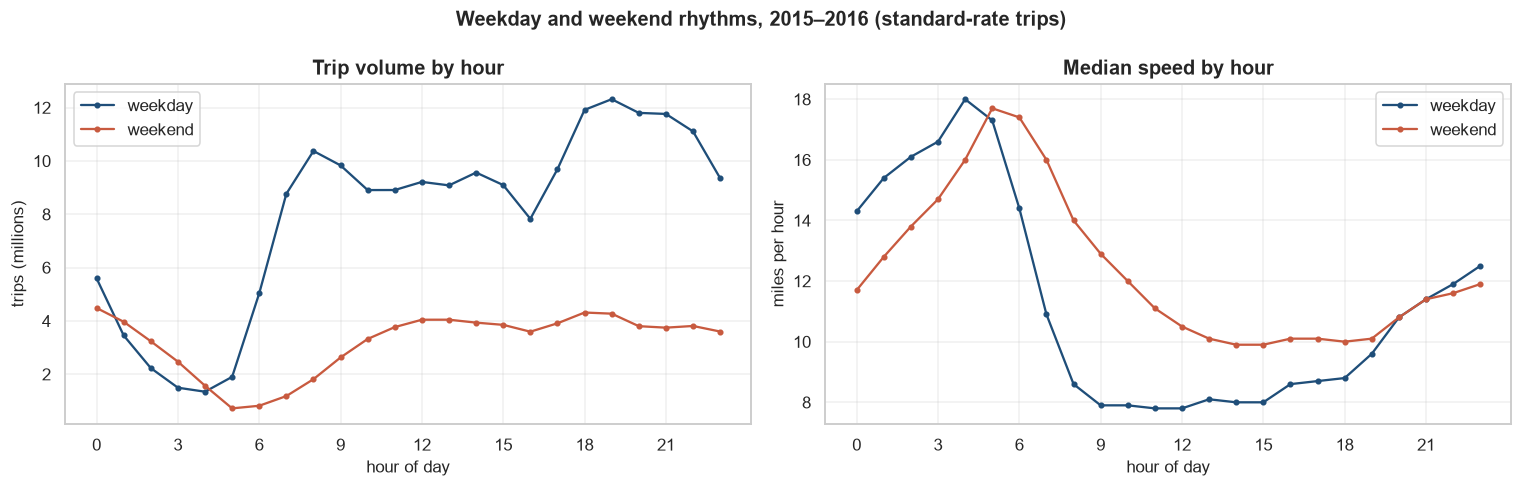

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

volume = hourly_pattern.pivot(index="hour", columns="day_type", values="trips")
speed = hourly_pattern.pivot(index="hour", columns="day_type", values="median_mph")

for column, colour in [("weekday", "#1f4e79"), ("weekend", "#c85a3f")]:
    axes[0].plot(volume.index, volume[column] / 1e6, color=colour, marker="o",
                 markersize=3, label=column)
    axes[1].plot(speed.index, speed[column], color=colour, marker="o",
                 markersize=3, label=column)

axes[0].set_title("Trip volume by hour")
axes[0].set_ylabel("trips (millions)")
axes[1].set_title("Median speed by hour")
axes[1].set_ylabel("miles per hour")

for axis in axes:
    axis.set_xlabel("hour of day")
    axis.set_xticks(range(0, 24, 3))
    axis.legend()

fig.suptitle("Weekday and weekend rhythms, 2015–2016 (standard-rate trips)",
             fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "08_hourly_patterns.png", dpi=110, bbox_inches="tight")
plt.show()

Weekday and weekend are two different regimes, not one pattern with variations.

Weekday volume rises steeply from 05:00 to a morning plateau around 09:00, drops from 9.1M to 7.8M at 16:00, then peaks at 19:00 with 12.3M trips. Weekend volume never rises above 4.3M and stays roughly flat from noon onwards. The two curves cross twice: weekends are busier between 01:00 and 04:00, weekdays are busier for the rest of the day. At 07:00 the gap is largest — 8.8M weekday trips against 1.2M on weekends.

The 16:00 dip is worth noting: volume falls for a single hour while median speed rises slightly, from 8.0 to 8.6 mph. If demand had dropped, speed would be unaffected — fewer passengers doesn't clear the roads. A simultaneous fall in trips and rise in speed points at supply rather than demand, but with no vehicle or driver identifier in the data, that stays a reading rather than a finding.

The speed panel shows congestion directly. Weekday speed falls from 18.0 mph at 04:00 to 7.8 mph by 11:00 and stays between 7.8 and 8.8 until 18:00 — seven hours where the city moves at roughly 8 mph. The same distance takes more than twice as long at midday as it does at dawn. Weekends bottom out at 9.9 mph, about 25% faster than weekday lows.

What the volume curve suggests and the speed curve contradicts is the morning rush. Volume peaks in the evening, but the sharpest speed drop happens in the morning: between 06:00 and 09:00 weekday speed falls from 14.4 to 7.9 mph, and it never recovers until after 19:00. Congestion is not a function of taxi volume — taxi trips peak at 19:00 when speeds are already improving. Something else fills the roads between 09:00 and 18:00, and this dataset cannot see it.

For feature engineering this means hour of day is a strong predictor but a cyclical one: hour 23 and hour 0 are adjacent in reality and twenty-three units apart numerically. Encoding it as a plain integer would teach a model that midnight is maximally distant from 11pm. And `day_type` is not optional — averaging the two regimes together would produce a curve that describes neither.

In [36]:
monthly_trend = con.execute(f"""
    SELECT
        strftime(tpep_pickup_datetime, '%Y-%m')  AS month,
        COUNT(*)                                 AS trips,
        ROUND(SUM(total_amount) / 1e6, 1)        AS revenue_musd,
        ROUND(MEDIAN(total_amount), 2)           AS median_fare,
        ROUND(MEDIAN(trip_distance), 2)          AS median_distance,
        ROUND(MEDIAN(date_diff('second', tpep_pickup_datetime,
              tpep_dropoff_datetime) / 60.0), 1) AS median_minutes
    FROM read_parquet('{TRIP_FILES}')
    WHERE tpep_pickup_datetime >= '{DATE_START}'
      AND tpep_pickup_datetime <  '{DATE_END}'
      AND trip_distance BETWEEN 0.1 AND 100
      AND total_amount BETWEEN 2.5 AND 500
      AND date_diff('second', tpep_pickup_datetime, tpep_dropoff_datetime) BETWEEN 60 AND 10800
    GROUP BY 1 ORDER BY 1
""").df()

display(monthly_trend.set_index("month"))

,trips,revenue_musd,median_fare,median_distance,median_minutes
month,,,,,
2015-01,12609651,186.1,11.16,1.70,10.0
2015-02,12314825,188.7,11.76,1.70,10.9
2015-03,13201589,207.5,11.80,1.70,11.0
2015-04,12928363,206.0,11.84,1.77,11.3
2015-05,13014288,213.2,12.30,1.80,11.5
2015-06,12189732,198.6,12.30,1.78,11.5
2015-07,11432166,183.7,11.80,1.80,11.1
2015-08,11000831,177.0,11.80,1.80,11.0
2015-09,11085864,181.7,12.30,1.80,11.4


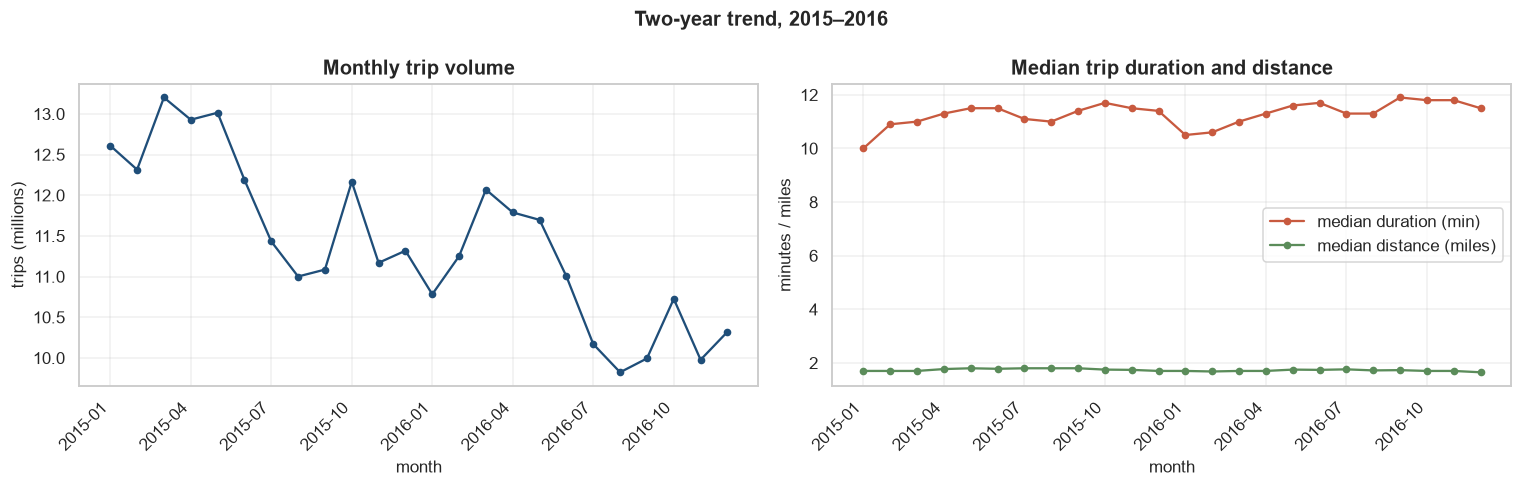

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

months = monthly_trend["month"]
tick_positions = range(0, len(months), 3)

axes[0].plot(months, monthly_trend["trips"] / 1e6, color="#1f4e79", marker="o", markersize=4)
axes[0].set_title("Monthly trip volume")
axes[0].set_ylabel("trips (millions)")

axes[1].plot(months, monthly_trend["median_minutes"], color="#c85a3f",
             marker="o", markersize=4, label="median duration (min)")
axes[1].plot(months, monthly_trend["median_distance"], color="#5b8c5a",
             marker="o", markersize=4, label="median distance (miles)")
axes[1].set_title("Median trip duration and distance")
axes[1].set_ylabel("minutes / miles")
axes[1].legend()

for axis in axes:
    axis.set_xlabel("month")
    axis.set_xticks(list(tick_positions))
    axis.set_xticklabels([months[i] for i in tick_positions], rotation=45, ha="right")

fig.suptitle("Two-year trend, 2015–2016", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "08_monthly_trend.png", dpi=110, bbox_inches="tight")
plt.show()

Volume falls steadily across the two years. The peak is 13.2M trips in March 2015; the low is 9.8M in August 2016 — a 26% decline over eighteen months. The seasonal shape repeats in both years: spring and autumn run high, August and January run low.

Revenue follows volume down but not as steeply: 186.1M dollars in January 2015 against 166.8M in December 2016, an 10% fall against a 18% fall in trips over the same months. Median fare rose from 11.16 to 11.90 dollars, which absorbs part of the volume loss.

The right panel holds the more interesting finding. Median distance stays flat at roughly 1.7 miles for the entire period, while median duration rises from 10.0 to 11.5 minutes. Trips are not getting longer; they are taking longer. That is a 15% increase in time spent covering the same ground.

Two readings fit. Either the city got more congested between 2015 and 2016, or the mix of trips shifted toward slower parts of it. The hourly analysis showed weekday speeds already sitting near 8 mph for seven hours a day, so further congestion is plausible, but this dataset holds only yellow taxi records — it cannot see what else is on the road, and it cannot distinguish a slower city from a changing trip mix.

What it does establish is that falling volume and rising duration happened together. Fewer trips, each taking more time, over the same distances, at slightly higher fares.

### What the time patterns showed

Three findings, each with a consequence for modelling.

Weekday and weekend are separate regimes. Volume differs by a factor of seven at 07:00, the daily shapes don't match, and the two curves cross in the early hours. A model trained on the combined data would learn an average that describes neither. `day_type` belongs in any feature set built from this data.

Hour of day drives both demand and speed, but it is cyclical. Encoded as an integer, hour 23 and hour 0 sit twenty-three units apart while being one hour apart in reality. Cyclical encoding is required, not optional.

Congestion is not driven by taxi volume. Speed bottoms out at 11:00 and stays there through 18:00, while trip volume peaks at 19:00 when speeds are already recovering. Whatever fills the roads during the working day is outside this dataset — a reminder that yellow taxi records describe one participant in the traffic, not the traffic.

The two-year trend adds a fourth: volume fell 26% while median duration rose 15% over constant distances. Both trends are clear in the data; the reason for either is not, and attributing them would require FHV records, weather, or roadworks data that this analysis doesn't have.

One technical detail worth carrying forward: timestamps are local New York time, confirmed by the daylight saving signature. Four dates in the two-year window carry an artificial dip or spike that has nothing to do with demand.

Location comes next — where trips start and end, and what happens when time and place are read together.

## 9. Location patterns

Every trip carries a pickup and a dropoff zone, joined to names through the lookup table. Three questions follow.

Which zones generate the most activity, and does the answer change depending on what "most" means? Trip count, total revenue, and revenue per trip can rank the same zones in different orders, and ranking by volume alone would hide anywhere that runs few but valuable trips.

Where do vehicles accumulate? Subtracting dropoffs from pickups per zone shows which areas send more passengers out than they take in, and which do the reverse. A zone with a large negative balance is somewhere drivers end up without a fare waiting.

And when time and location are combined: does the busiest zone stay busiest all day, or does the map change by hour?

Before any of that, the lookup table itself needs a look — it maps zone IDs to names and boroughs, and the data quality section flagged 1.9% of trips as carrying an unknown zone. The query below shows which IDs those are.

In [38]:
zone_lookup = con.execute(f"""
    SELECT LocationID, Borough, Zone, service_zone
    FROM read_csv_auto('{ZONE_LOOKUP}')
    WHERE LocationID IN (264, 265) OR LocationID <= 3
    ORDER BY LocationID
""").df()

display(zone_lookup.set_index("LocationID"))

,Borough,Zone,service_zone
LocationID,,,
1,EWR,Newark Airport,EWR
2,Queens,Jamaica Bay,Boro Zone
3,Bronx,Allerton/Pelham Gardens,Boro Zone
264,Unknown,N/A,N/A
265,N/A,Outside of NYC,N/A


The two IDs mean different things. 264 is genuinely unknown: borough, zone, and service zone all read as placeholders, so these are records where the location could not be resolved. 265 is labelled "Outside of NYC" — not a failure but a real category, covering trips that started or ended beyond the city boundary.

Both get excluded from the zone analysis that follows, for different reasons. 264 carries no location information at all. 265 does, but only that the trip left the mapped area; treating it as a zone would put a category covering everything from Westchester to New Jersey alongside individual Manhattan neighbourhoods.

The first three rows show the normal structure: each ID maps to a named zone within a borough, with a `service_zone` label alongside it.

In [39]:
zone_ranking = con.execute(f"""
    SELECT
        zone.Zone                                AS zone_name,
        zone.Borough                             AS borough,
        COUNT(*)                                 AS trips,
        ROUND(SUM(trip.total_amount) / 1e6, 1)   AS revenue_musd,
        ROUND(AVG(trip.total_amount), 2)         AS revenue_per_trip,
        ROUND(MEDIAN(trip.trip_distance), 2)     AS median_distance
    FROM read_parquet('{TRIP_FILES}') AS trip
    JOIN read_csv_auto('{ZONE_LOOKUP}') AS zone
      ON trip.PULocationID = zone.LocationID
    WHERE trip.PULocationID NOT IN (264, 265)
      AND trip.total_amount BETWEEN 2.5 AND 500
      AND trip.trip_distance BETWEEN 0.1 AND 100
    GROUP BY 1, 2
    ORDER BY trips DESC
    LIMIT 20
""").df()

display(zone_ranking.set_index("zone_name"))

,borough,trips,revenue_musd,revenue_per_trip,median_distance
zone_name,,,,,
Upper East Side South,Manhattan,10241799,124.9,12.19,1.30
Midtown Center,Manhattan,9695178,143.8,14.83,1.50
Upper East Side North,Manhattan,9309841,118.6,12.74,1.49
Penn Station/Madison Sq West,Manhattan,9122399,132.2,14.49,1.55
Midtown East,Manhattan,9062273,135.2,14.92,1.59
Union Sq,Manhattan,9005181,124.5,13.82,1.46
East Village,Manhattan,8956009,130.8,14.60,1.80
Murray Hill,Manhattan,8884884,126.7,14.26,1.49
Times Sq/Theatre District,Manhattan,8841493,143.4,16.22,1.60


Ranking by trip count produces a list that is almost entirely Manhattan: eighteen of the top twenty zones, all with median distances between 1.30 and 1.80 miles. Upper East Side South leads with 10.2M pickups.

Ranking by revenue produces a different list. JFK Airport sits sixteenth by volume but first by revenue — 331.8M dollars against 143.8M for Midtown Center, the highest-earning Manhattan zone. LaGuardia is second at 285.4M. Between them the two airports generate 617M dollars from 12.7M trips, while the top five Manhattan zones together produce 655M from 47.4M trips. Roughly a quarter of the trips, nearly the same revenue.

Revenue per trip explains it: 56.04 dollars at JFK and 42.36 at LaGuardia, against 12 to 16 dollars everywhere in Manhattan. Median distance follows the same split — 17.60 miles from JFK, 9.80 from LaGuardia, and 1.30 to 1.80 miles across the Manhattan zones.

This is why a single metric can't rank locations. Volume says Manhattan is where the business is. Revenue per trip says the airports are. Both are true, and they imply different operational decisions: one favours density and short turnaround, the other favours fewer, longer, higher-value trips.

The Manhattan zones themselves vary less than expected. Revenue per trip ranges from 12.19 at Upper East Side South to 16.22 at Times Square — a 33% spread across eighteen zones, against a 4.6x gap between Manhattan and JFK.

In [40]:
zone_flow = con.execute(f"""
    WITH pickups AS (
        SELECT PULocationID AS zone_id, COUNT(*) AS pickups
        FROM read_parquet('{TRIP_FILES}')
        WHERE PULocationID NOT IN (264, 265)
        GROUP BY 1
    ),
    dropoffs AS (
        SELECT DOLocationID AS zone_id, COUNT(*) AS dropoffs
        FROM read_parquet('{TRIP_FILES}')
        WHERE DOLocationID NOT IN (264, 265)
        GROUP BY 1
    )
    SELECT
        zone.Zone                                  AS zone_name,
        zone.Borough                               AS borough,
        pickups.pickups,
        dropoffs.dropoffs,
        pickups.pickups - dropoffs.dropoffs        AS net_flow
    FROM pickups
    JOIN dropoffs USING (zone_id)
    JOIN read_csv_auto('{ZONE_LOOKUP}') AS zone ON zone.LocationID = pickups.zone_id
    ORDER BY ABS(pickups.pickups - dropoffs.dropoffs) DESC
    LIMIT 15
""").df()

display(zone_flow.set_index("zone_name"))

,borough,pickups,dropoffs,net_flow
zone_name,,,,
JFK Airport,Queens,6081369,2443679,3637690
LaGuardia Airport,Queens,6774654,3371278,3403376
East Village,Manhattan,9000807,7246342,1754465
Penn Station/Madison Sq West,Manhattan,9167739,7612531,1555208
East Harlem South,Manhattan,1676456,3053092,-1376636
Upper East Side South,Manhattan,10282360,8906728,1375632
Clinton East,Manhattan,8704438,7415005,1289433
Union Sq,Manhattan,9045625,7798225,1247400
West Village,Manhattan,6029379,4782413,1246966


The airports dominate the positive side. JFK sends out 3.6M more passengers than it receives, LaGuardia 3.4M — each takes in roughly half the trips it generates.

Three zones run large negative balances, and two of them are the East Harlem pair: East Harlem South at -1.4M and East Harlem North at -1.1M. Passengers are dropped there far more often than they are picked up — 3.1M dropoffs against 1.7M pickups in the south zone, 2.0M against 0.9M in the north. A driver ending a trip in East Harlem has a poor chance of finding the next fare without moving.

West Chelsea/Hudson Yards is the third, at -1.0M, with 5.1M dropoffs against 4.1M pickups.

Everything else in the top fifteen is a Manhattan zone with a positive balance between 1.0M and 1.8M. Each of these zones sends out more passengers than it takes in.

This table is the closest thing in the data to a measure of empty running. A driver's unproductive mileage is not recorded anywhere — the dataset contains only metered trips — but a zone with a large negative balance is, by construction, somewhere vehicles accumulate without fares. That makes it the natural starting point for a repositioning problem, with one important limitation: the data records trips that happened, not demand that went unserved. Few pickups in a zone can mean two things — nobody wanted a taxi there, or somebody did and none was available. These records cannot tell the two apart.

Six zones, each taken from a table earlier in this section rather than chosen by hand: the four busiest pickup zones by trip count, the highest-revenue zone (JFK Airport), and the zone with the largest positive net flow outside the airports (East Village). Each line shows what share of that zone's own weekday pickups falls in each hour, so zones of very different sizes can be compared on shape.

In [41]:
TOP_ZONES = ["Upper East Side South", "Midtown Center", "Upper East Side North",
             "Penn Station/Madison Sq West", "JFK Airport", "East Village"]
zone_list = ", ".join(f"'{zone}'" for zone in TOP_ZONES)

zone_by_hour = con.execute(f"""
    SELECT
        zone.Zone                                    AS zone_name,
        EXTRACT(hour FROM trip.tpep_pickup_datetime) AS hour,
        COUNT(*)                                     AS trips
    FROM read_parquet('{TRIP_FILES}') AS trip
    JOIN read_csv_auto('{ZONE_LOOKUP}') AS zone
      ON trip.PULocationID = zone.LocationID
    WHERE zone.Zone IN ({zone_list})
      AND EXTRACT(dow FROM trip.tpep_pickup_datetime) BETWEEN 1 AND 5
    GROUP BY 1, 2 ORDER BY 1, 2
""").df()

hourly_share = zone_by_hour.pivot(index="hour", columns="zone_name", values="trips")
hourly_share = 100 * hourly_share / hourly_share.sum()

display(hourly_share.round(1))

zone_name,East Village,JFK Airport,Midtown Center,Penn Station/Madison Sq West,Upper East Side North,Upper East Side South
hour,,,,,,
0,6.0,4.5,2.7,2.4,0.8,1.1
1,4.2,2.3,1.4,1.4,0.4,0.5
2,2.9,0.7,0.7,0.9,0.2,0.3
3,2.0,0.3,0.4,0.5,0.1,0.2
4,1.7,0.3,0.4,0.6,0.2,0.2
5,1.3,2.2,0.5,1.3,0.8,0.6
6,2.5,4.2,1.3,5.4,2.8,1.9
7,3.4,4.1,2.6,6.6,6.1,5.0
8,3.5,3.1,3.7,5.7,7.3,6.4


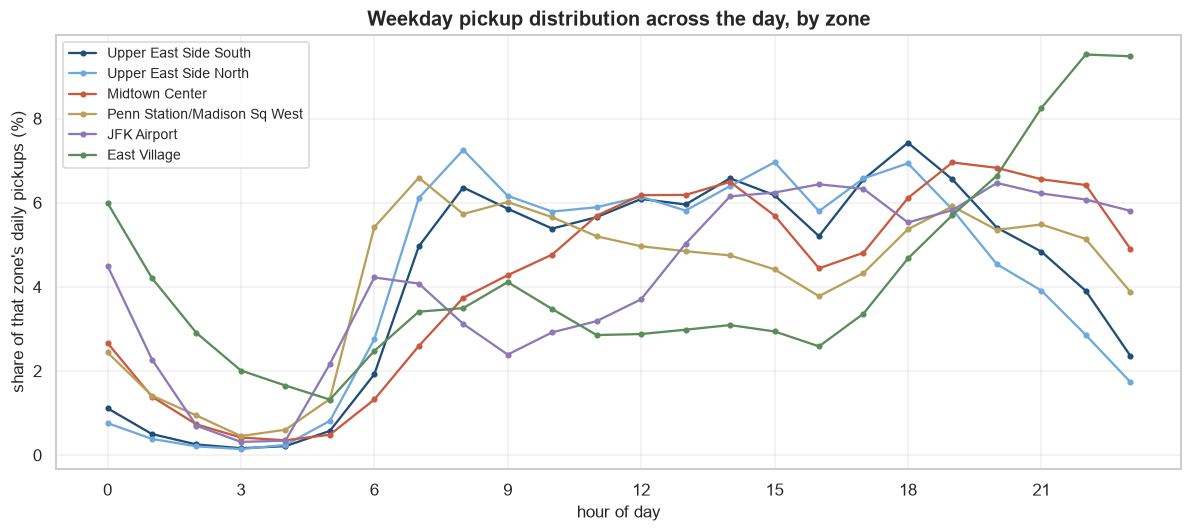

In [42]:
ZONE_COLOURS = {
    "Upper East Side South": "#1f4e79",
    "Upper East Side North": "#6fa8dc",
    "Midtown Center": "#c85a3f",
    "Penn Station/Madison Sq West": "#b8a05b",
    "JFK Airport": "#8c7ab8",
    "East Village": "#5b8c5a",
}

fig, axis = plt.subplots(figsize=(11, 5))
for zone_name, colour in ZONE_COLOURS.items():
    axis.plot(hourly_share.index, hourly_share[zone_name], marker="o",
              markersize=3, color=colour, label=zone_name)

axis.set_title("Weekday pickup distribution across the day, by zone")
axis.set_xlabel("hour of day")
axis.set_ylabel("share of that zone's daily pickups (%)")
axis.set_xticks(range(0, 24, 3))
axis.legend(fontsize=9)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "09_zone_by_hour.png", dpi=110, bbox_inches="tight")
plt.show()

The six zones follow different daily rhythms; the exact shares are in the table above.

Penn Station starts earliest. At 06:00 it already holds 5.4% of its daily pickups — the highest share of any zone at that hour — and peaks at 07:00 with 6.6%. Its share then declines through the afternoon to 3.8% at 16:00 and recovers to 5.9% by 19:00.

The two Upper East Side zones follow the same shape: a sharp rise between 06:00 and 08:00, a daytime plateau between about 5% and 7.5%, and a steady fall after 19:00. They differ in where the weight sits. Upper East Side North peaks in the morning, 7.3% at 08:00; Upper East Side South peaks in the evening, 7.4% at 18:00. North's share also falls faster at night — 2.9% at 22:00 against 3.9% for South. The two adjacent zones have similar but not identical profiles.

Midtown Center builds through the morning, holds 6.2–6.5% from 12:00 to 14:00, and peaks at 19:00 with 7.0%.

East Village runs the opposite shape. Between 10:00 and 17:00 its share stays between 2.6% and 3.5%, then rises every hour from 17:00 to reach 9.5% at both 22:00 and 23:00 — the highest hourly shares in the table. At midnight it still holds 6.0%, when Upper East Side South holds 1.1%.

JFK has the flattest profile from the afternoon on: between 14:00 and 22:00 its share stays within 5.5–6.5% for nine consecutive hours.

One pattern runs across all five Manhattan zones: each dips at 16:00 and recovers at 17:00. JFK does not. The same one-hour dip appeared in the citywide volume curve in the time section; seeing it in every Manhattan zone separately shows it isn't driven by any single location.

The practical consequence is that a single citywide demand model would fit none of these zones well. At 08:00 Upper East Side South carries 6.4% of its daily pickups and East Village 3.5%; at 22:00 the order reverses, 3.9% against 9.5%. Any demand forecast has to work at the zone-hour level rather than treating hour of day as a citywide variable.

### What the location patterns showed

Ranking zones by trip count and ranking them by revenue produce different lists. Eighteen of the twenty busiest pickup zones are in Manhattan, all with median distances under 1.8 miles and fares between 12 and 16 dollars. JFK sits sixteenth by volume and first by revenue, at 56.04 dollars per trip. The two airports together generate about as much revenue as the top five Manhattan zones combined, from a quarter of the trips.

The imbalance in vehicle flow is not random but concentrated in specific zones. The airports send out roughly twice as many passengers as they take in. East Harlem does the reverse — 3.1M dropoffs against 1.7M pickups in the south zone alone. That imbalance is the closest thing this data holds to a measure of empty running, and it is where a repositioning problem would start, subject to the limitation that unserved demand leaves no record.

Time and location interact strongly enough that neither can be modelled without the other. East Village holds 9.5% of its daily pickups at 22:00 while Upper East Side South holds 3.9%; at 08:00 the order reverses, 3.5% against 6.4%. Hour of day is not a citywide variable.

Three things follow for feature work: pickup and dropoff zone belong in any model, hour of day has to interact with zone rather than stand alone, and net flow per zone is worth deriving as a feature in its own right.

The next section takes these findings and asks what they mean for a taxi platform — which problems the data can support, which features are worth building, and what has to be fixed first.

## 10. Business perspective

The question this analysis started from was how far a taxi platform could go on the AI side. Nine sections of evidence later, the answer separates into what this data supports now, what it could support with additions, and what it cannot support at all.

### What the data can support today

**Trip duration prediction.** The target is clean: two timestamps, present in every row, with impossible values identifiable and filterable. Features available at pickup — zone, hour, day type, rate code — all showed strong relationships with duration in the time and location sections. Nothing here requires data the platform wouldn't have at the moment of prediction.

**Fare prediction, with care.** `fare_amount` correlates 0.930 with distance, but distance is unknown at pickup. A usable model would have to predict fare from origin, destination, time, and rate code alone — harder, and lower-scoring, but it would run in production. The alternative scores better in testing and cannot be deployed.

**Zone-level demand forecasting.** This requires reshaping the data rather than modelling it as-is: individual trips become counts per zone per hour. The location section showed zone-hour patterns strong enough to predict, and the two-year span gives two full seasonal cycles to learn from.

### What needs more than this data

**Vehicle repositioning.** The net flow table identifies where vehicles accumulate without fares, which is the starting point. But the data records only completed trips, so a model would learn where demand was met, not where it existed. Deploying such a model creates a feedback loop: drivers follow its recommendations, the pattern of served demand shifts, and the next model trains on the consequences of the last one. This needs live request logs and an experimentation framework, not more historical trips.

**Anything driver- or vehicle-level.** No medallion, no licence number, no vehicle identifier. Driver performance, fleet utilisation, and per-vehicle maintenance patterns are all outside what these records can describe, regardless of how they're aggregated.

### What the data cannot support

**Tip prediction.** Cash payments record zero tips in 100% of 96.4M trips. A model fitted on the full data would predict payment method. Restricted to card payments it becomes technically possible, but the result describes card-paying passengers only.

**Route optimisation.** No route geometry, no waypoints, no street network. The data knows where a trip started and ended, not how it got there.

**Customer satisfaction.** There is no rating, no complaint, no cancellation, and no wait time in these records. The only proxy is tip amount, which the tip finding rules out.

### Features worth deriving

Everything below can be computed at pickup. That is a requirement rather than a preference: a feature derived from information that only exists after the trip ends cannot be used to predict anything about that trip.

**From the timestamp.** Hour of day, encoded cyclically so 23:00 and 00:00 sit next to each other rather than twenty-three units apart. Day of week, and a weekday/weekend flag, since the time section showed these are separate regimes rather than variations on one. Month, which carries the seasonal pattern that repeated across both years.

**From the zones.** Pickup and dropoff zone as categorical features, plus borough as a coarser grouping for zones with thin data. The zone pair carries information too — Manhattan-to-JFK behaves differently from Manhattan-to-Manhattan in both distance and fare — but pairing 260 zones produces tens of thousands of categories. It needs coarsening to borough pairs, or keeping only the frequent combinations separate.

**From zone and time together.** Median speed per zone-hour, computed from historical data, gives a congestion estimate available before the trip starts. Net flow per zone-hour, from the pickup-minus-dropoff calculation, estimates how easily a driver finds the next fare. Both are aggregates rather than row-level values, which means they have to be computed from a training window and joined in, not derived from the row being predicted.

**From the rate code.** An airport flag from `RatecodeID` 2 and 3, since those trips have fixed fares and distances an order of magnitude above the Manhattan median. A negotiated-fare flag from code 5, where the fare-distance relationship breaks down entirely.

**Quality flags rather than filters.** A marker for records failing the physical checks — impossible distance, duration, or amount — and a marker for the fixed-fee mismatches found in the data quality section. Keeping these as columns rather than dropping the rows lets a downstream step decide what to exclude, with the row count preserved for auditing.

**What not to build.** Anything derived from `trip_distance`, `duration`, `fare_amount`, or `total_amount` is unavailable at prediction time and belongs only in the target. `passenger_count` correlates 0.011 with the total amount and partly encodes which vendor recorded the trip — it carries little and risks confounding.

### The three biggest problems in this data

**1. Missingness is disguised as valid values.** Seventeen of nineteen columns contain no nulls at all, which reads as clean data until the checks go deeper. Zero distances, zero passenger counts, and placeholder zone codes all occupy the space where nulls would be. A pipeline that trusts `isnull()` would carry 5.3M unresolved locations, 1.7M zero-distance trips, and 54,114 zero-passenger records straight into training as if they were measurements. The model then learns that some trips genuinely cover no ground and carry nobody.

**2. Tips are structurally absent for a third of the data.** Cash payments record zero tips in 100% of 96.4M trips. This is not noise that averaging will handle — it is a systematic gap tied to one value of one column. Any model touching `tip_amount` on the full dataset is fitting payment method. Reported without the caveat, the resulting numbers would understate actual tipping by a wide margin and the error would be invisible in every validation metric.

**3. The target-defining columns are unavailable at prediction time.** `trip_distance` correlates 0.930 with fare and 0.831 with duration, which makes it the most tempting feature in the dataset and an unusable one. Distance, duration, and final fare all come into existence when the trip ends. A model built on them validates beautifully and fails on contact with production, where a prediction is needed before the meter starts. This is the failure that costs the most to discover late, because nothing in the testing process reveals it.

Each of these would produce a model that scores well and behaves wrongly. The first corrupts the inputs, the second corrupts the target, the third corrupts the relationship between them — and none of the three announces itself in a validation score.

## 11. Findings and next steps

277M trips across 24 months, examined for structure, quality, distribution, and pattern. What the analysis established, in short:

**The dataset is more consistent than expected and less clean than it looks.** All 24 files share an identical schema — no breaks, no dtype drift, no missing columns. Nulls are effectively absent. But the data quality checks found 5.3M unresolved locations, 1.7M zero-distance trips, 107K refund records, and a set of corrupted extremes reaching 59 million miles and 825,998 dollars. None of it appears as a null.

**Distributions are right-skewed with contaminated tails.** Median trip: 1.7 miles, 11 minutes, 11.50 dollars. Mean and standard deviation are unusable on the raw columns — standard deviation for distance reaches 8,327 against a p99 of 18.6. Rank-based statistics were used throughout for this reason.

**On outliers, the choice of scale and parameter mattered more than the choice of method.** With default parameters IQR flagged 28M rows and three-sigma flagged none. IQR on the log scale and a sigma rule using the MAD gave bounds very close to p99. Every bound at this level largely separates airport trips, so fixed-fare trips should be separated by `RatecodeID`, not by a threshold. On correlation, running Pearson and Spearman together revealed two relationships that either method alone would have misread.

**Categorical columns are heavily imbalanced and contain undocumented codes.** `RatecodeID` is 97.3% one class. `VendorID = 3` and `RatecodeID = 99` appear in the data but not the dictionary.

**Time and location interact and cannot be separated.** Weekday and weekend are distinct regimes. Zone-hour patterns reverse across the day — at 08:00 Upper East Side South carries nearly twice East Village's share, and at 22:00 East Village carries more than twice Upper East Side South's. Volume fell 26% over the two years while median duration rose 15% over constant distances.

**Three problems would break a model quietly:** missingness written as valid values, tips structurally absent for a third of the data, and the most predictive columns being unavailable at prediction time.

### What was left out

Every item in the plan set out in Section 1 was covered. The exclusions stated there also stand: green taxi and FHV data were not examined, weather and holiday calendars were not pulled, and no modelling or prediction was done. Questions that arose during the analysis and could not be answered from this data were noted in their own sections — the absence of vehicle and driver identifiers, the lack of any record of unserved demand, and the absence of route geometry.

### Next steps

The immediate next stage is feature engineering, and this analysis defines its inputs: cyclical time encodings, zone and borough categoricals, zone-hour aggregates for congestion and net flow, rate-code flags, and quality markers carried as columns rather than applied as filters.

Two decisions belong to the modelling stage rather than here. Where exactly to cut the tail depends on the target variable — a duration model and a fare model tolerate different amounts of the extreme. And which of `fare_amount` and `total_amount` to keep depends on whether the target should include tips and tolls.

Three additional sources would widen the range of questions this data can answer. FHV and green taxi records would show whether the volume decline was a transfer to other services or a contraction of demand. Weather and event calendars would separate congestion from seasonal effects. Request-level logs — including trips that were never served — would turn the repositioning problem from an observational one into a solvable one.